# <center> Initial comparisons

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc
import akantu as aka

# plotting parameters
plt.rcParams.update(
    {
        # Figure
        "figure.figsize": (9, 6),
        "figure.dpi": 300,
        # Font
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman"],
        "font.size": 14,
        # Titles and labels
        "axes.titlesize": 20,
        "axes.titleweight": "bold",
        "axes.labelsize": 15,
        # Tick labels
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        # Lines and markers
        "lines.linewidth": 2,
        "lines.markersize": 6,
        # Legend
        "legend.fontsize": 15,
        "legend.frameon": True,
        # Grid
        "axes.grid": True,
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
        "grid.alpha": 0.5,
        # Axes
        "axes.linewidth": 1.0,
        # Saving figures
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        # Mathematical text
        "mathtext.fontset": "stix",
    }
)

# Colours I liked
COLORS = {
    "blue": "#5F8FAF",
    "orange": "#E6A15C",
    "red": "#D97A7A",
    "green": "#7FB685",
    "purple": "#A58CC2",
}

In [16]:
# Plotters

# ============================================================================ #
def plot_energy_evolution(path, N):
    run_path = get_run_path(path, N)
    
    if not (run_path / "energies.out").exists():
        data = read_output_file(run_path / "energies_pf.out")
    else:
        data = read_output_file(run_path / "energies.out")

    time = data["time"] * 1e6
    E0 = data["total_energy"].iloc[0]
    conserved_energy = data["total_energy"] - data["external_work"]

    plt.figure()
    plt.plot( time, data["kinetic_energy"], label="Kinetic", 
             color=COLORS["blue"])
    plt.plot(time, data["elastic_energy"], label="Elastic",
             color=COLORS["orange"],)

    if "reversible_cohesive_energy" in data.columns:
        plt.plot(time, data["reversible_cohesive_energy"], 
                 label="Reversible cohesive", color=COLORS["purple"])

    plt.plot(time, data["fracture_energy"], label="Fracture",
             color=COLORS["red"])

    if "contact_energy" in data.columns:
        plt.plot(time, data["contact_energy"], label="Contact", 
                 color=COLORS["green"])

    plt.plot(time, data["total_energy"], label="Total", color="black")
    plt.plot(time, conserved_energy, label="Injected", color="gray",
             linestyle="--")

    plt.xlabel(r"Time [$\mu$s]")
    plt.ylabel("Energy [J]")
    plt.title(f"Energy evolution, N = {N}")
    plt.legend()

    plt.show()

# ============================================================================ #
def plot_fragment_distribution(path, N):
    run_path = get_run_path(path, N)
    if not (run_path / "energies.out").exists():
        fragments = read_output_file(run_path / "fragments_pf.out")
    else:
        fragments = read_output_file(run_path / "fragments.out")

    if "time" in fragments.columns:
        final_time = fragments["time"].max()
        fragments = fragments[np.isclose(fragments["time"], final_time)]

    sizes = fragments["size"]

    plt.figure()
    plt.hist(sizes, bins="auto", edgecolor="black", color=COLORS["blue"],)
    plt.axvline(sizes.mean(),linestyle="--",color=COLORS["red"],
                label=f"Mean = {sizes.mean():.3e} m")
    plt.xlabel("Fragment size [m]")
    plt.ylabel("Number of fragments")
    plt.title(f"Final fragment-size distribution, N = {N}")
    plt.legend()

    plt.show()

# ============================================================================ #
def plot_velocity_distribution(path, N):
    run_path = get_run_path(path, N)
    fields_path = run_path / "fields"

    nodal_files = list(fields_path.glob("nodal_*.out"))

    if not nodal_files:
        raise FileNotFoundError(f"No nodal files found in {fields_path}")

    final_file = max(nodal_files, 
                     key=lambda file: int(file.stem.split("_")[-1]))
    data = read_output_file(final_file)
    order = np.argsort(data["x"])
    x = data["x"].to_numpy()[order]
    velocity = data["velocity"].to_numpy()[order]

    plt.figure()
    plt.plot(x, velocity, color=COLORS["blue"])
    plt.xlabel("Position [m]")
    plt.ylabel("Velocity [m/s]")
    plt.title(f"Final velocity distribution, N = {N}")
    plt.show()

# ============================================================================ #
def plot_fragment_number_vs_N(path, N_values):
    fragment_numbers = []

    for N in N_values:
        run_path = get_run_path(path, N)
        if not (run_path / "energies.out").exists():
            data = read_output_file(run_path / "energies_pf.out")
        else:
            data = read_output_file(run_path / "energies.out")
        fragment_numbers.append(data["num_fragments"].iloc[-1])

    plt.figure()

    plt.plot(N_values, fragment_numbers, marker="o", color=COLORS["blue"])

    plt.xlabel("Number of elements N")
    plt.ylabel("Final number of fragments")
    plt.title("Fragment number convergence")
    plt.show()

# ============================================================================ #
def locate_final_fragment_time(path, N):
    """
    Locate the first fragment-count check from which the fragment number
    remains equal to its final value.

    Returns:
        completion_time
        sampling_interval
    """
    run_path = get_run_path(path, N)

    if not (run_path / "energies.out").exists():
        data = read_output_file(run_path / "energies_pf.out")
    else:
        data = read_output_file(run_path / "energies.out")

    dt = data["dt"].iloc[0]

    log_file = run_path / f"run_{N}.log"

    if not log_file.exists():
        log_file = run_path / f"run_{N}.out"

    steps = []
    fragments = []

    with open(log_file, "r") as file:
        for line in file:
            if line.startswith("Step:"):
                parts = line.split("--")
                step = int(parts[0].split(":")[1].strip())
                num_fragments = int(parts[1].split("=")[1].strip())
                steps.append(step)
                fragments.append(num_fragments)

    if not fragments:
        raise ValueError(f"No fragment-count checks found in {log_file}")

    final_num_fragments = fragments[-1]

    i = len(fragments) - 1

    while i > 0 and fragments[i - 1] == final_num_fragments:
        i -= 1

    final_fragment_step = steps[i]

    completion_time = final_fragment_step * dt

    # Fragment count is checked every 1000 steps
    sampling_interval = 1000 * dt

    return completion_time, sampling_interval


# ============================================================================ #
def plot_simulation_time(path, Ns):
    ts = []
    sampling_errors = []

    for N in Ns:
        t, sampling_interval = locate_final_fragment_time(path, N)

        ts.append(t)
        sampling_errors.append(sampling_interval)

    # True event can have occurred up to one sampling interval earlier,
    # but not later than the detected check.
    yerr = np.array([
        sampling_errors,
        np.zeros(len(sampling_errors))
    ])

    plt.figure()
    plt.plot(Ns, ts, marker="o", color=COLORS["blue"])
    plt.fill_between(Ns, np.array(ts) - np.array(sampling_errors), np.array(ts),
                     color=COLORS["orange"], alpha=0.2)
    #plt.errorbar(Ns, ts,yerr=yerr,marker="o", color=COLORS["blue"], capsize=4)
    plt.xlabel("Number of elements N")
    plt.ylabel("Fragmentation completion time [s]")
    plt.title("Fragmentation completion time vs number of elements")

    plt.show()

# ============================================================================ #
#number of fragments evolution
def plot_fragment_number_evolution(path, N, limit=None):
    run_path = get_run_path(path, N)

    steps = []
    fragments = []

    file = f"run_{N}.log"
    with open(run_path / file, "r") as file:
        for line in file:
            if line.startswith("Step:"):
                # Example:
                # Step: 168000 -- fragments = 14 -- stable checks = 0/500
                parts = line.split("--")
                step = int(parts[0].split(":")[1].strip())
                n_fragments = int(parts[1].split("=")[1].strip())
                steps.append(step)
                fragments.append(n_fragments)

    plt.figure()
    plt.step(steps, fragments, where="post")
    if limit is not None:
        plt.xlim(0, limit)
    plt.xlabel("Step")
    plt.ylabel("Number of fragments")
    plt.title(f"Fragment evolution, N = {N}")

    plt.show()
    

---
## <center> Mesh convergence of CZM

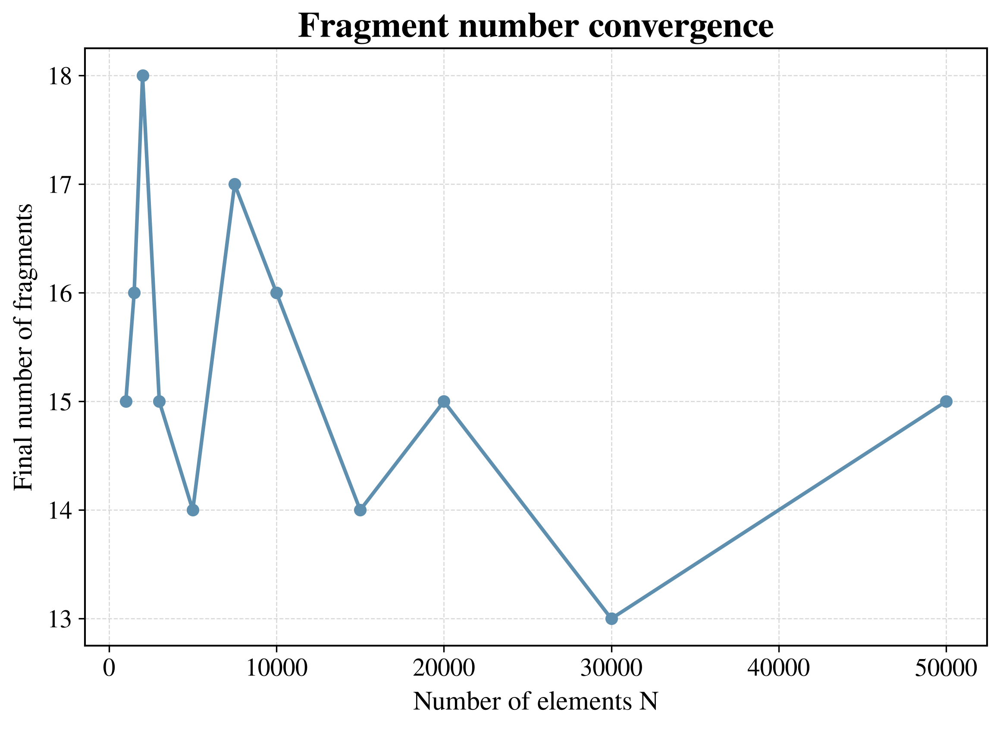

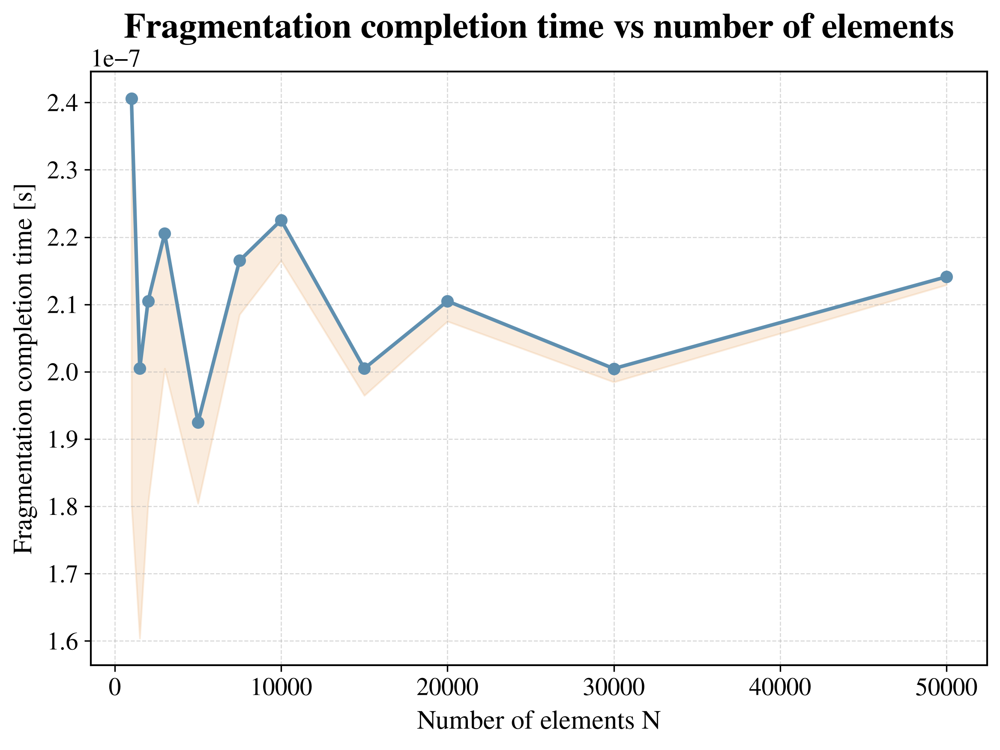

In [17]:
Ns = [1000, 1500, 2000, 3000, 5000, 7500,
      10000, 15000, 20000, 30000, 50000, 
      #75000, 
      #100000, 125000, 150000, 200000
      ]

path = Path("data/CZM/mesh_convergence")

#plot_energy_evolution(path, 50000)
#plot_fragment_distribution(path, 50000)
#plot_velocity_distribution(path, 50000)

plot_fragment_number_vs_N(path, Ns)
plot_simulation_time(path, Ns)

---
## <center> Mesh convergence for Phase Field

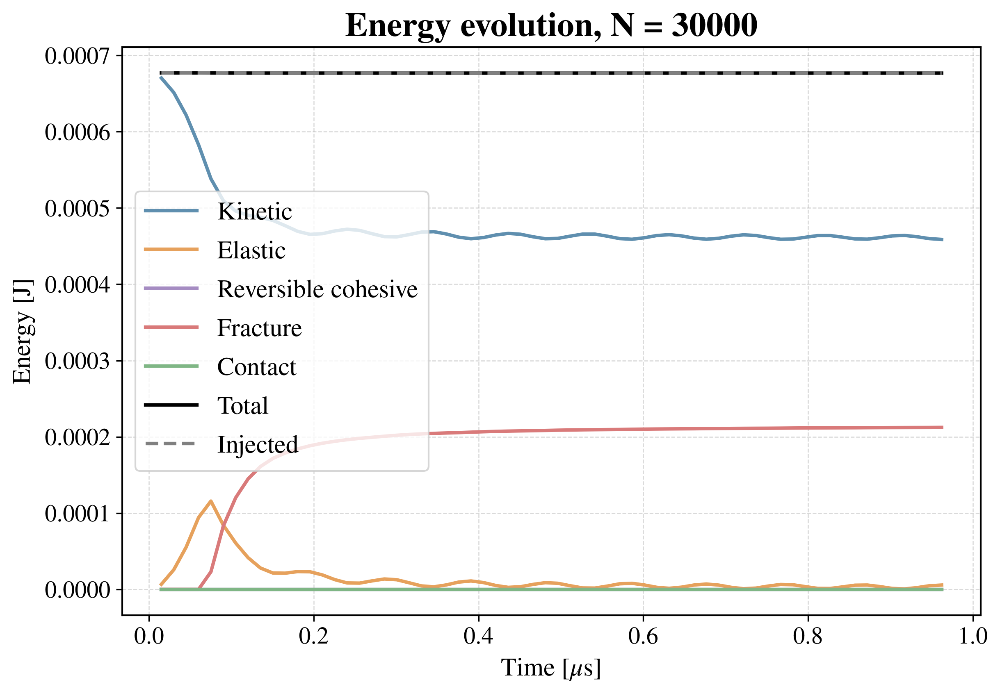

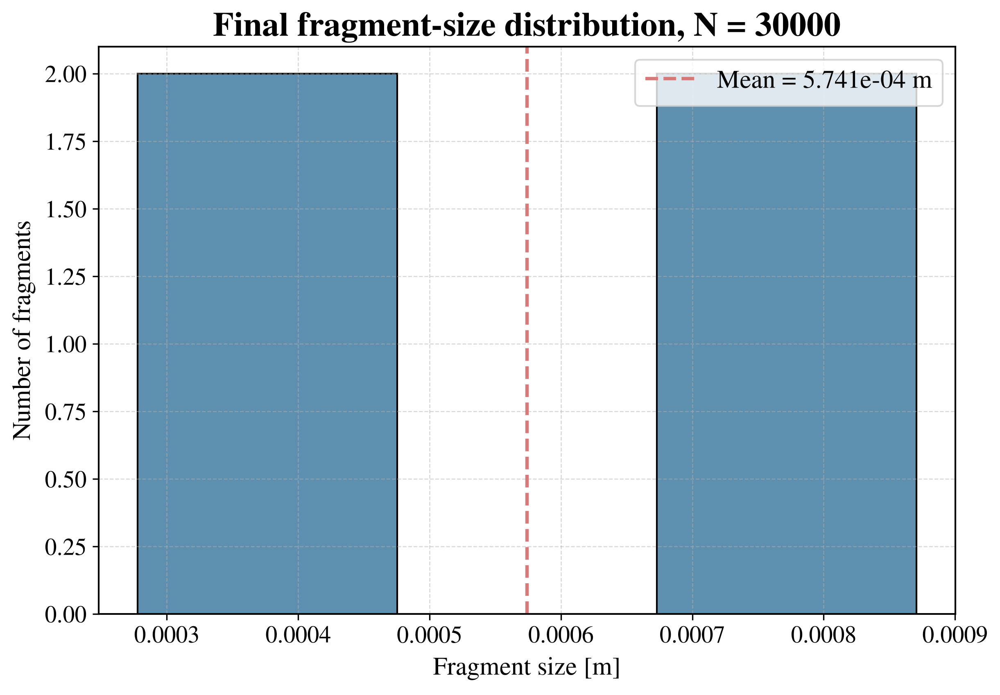

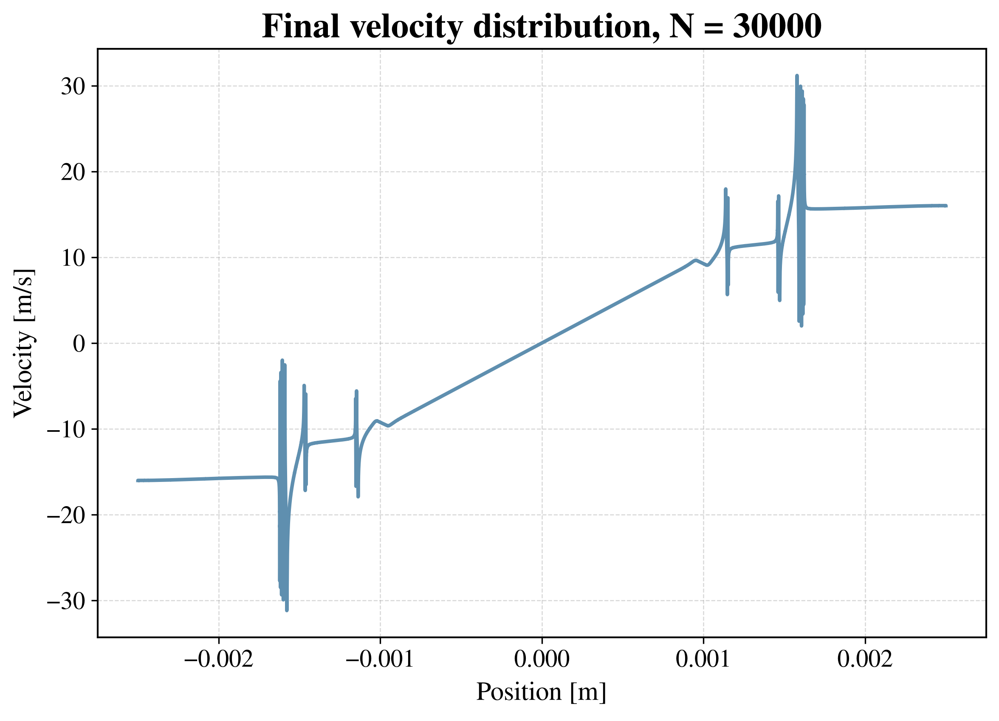

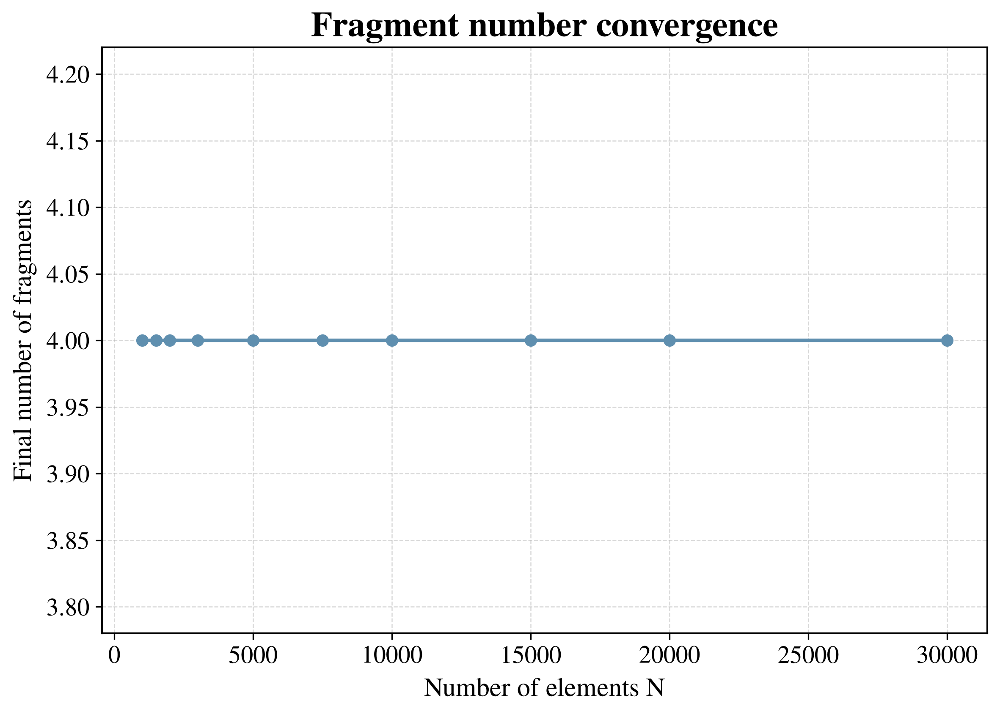

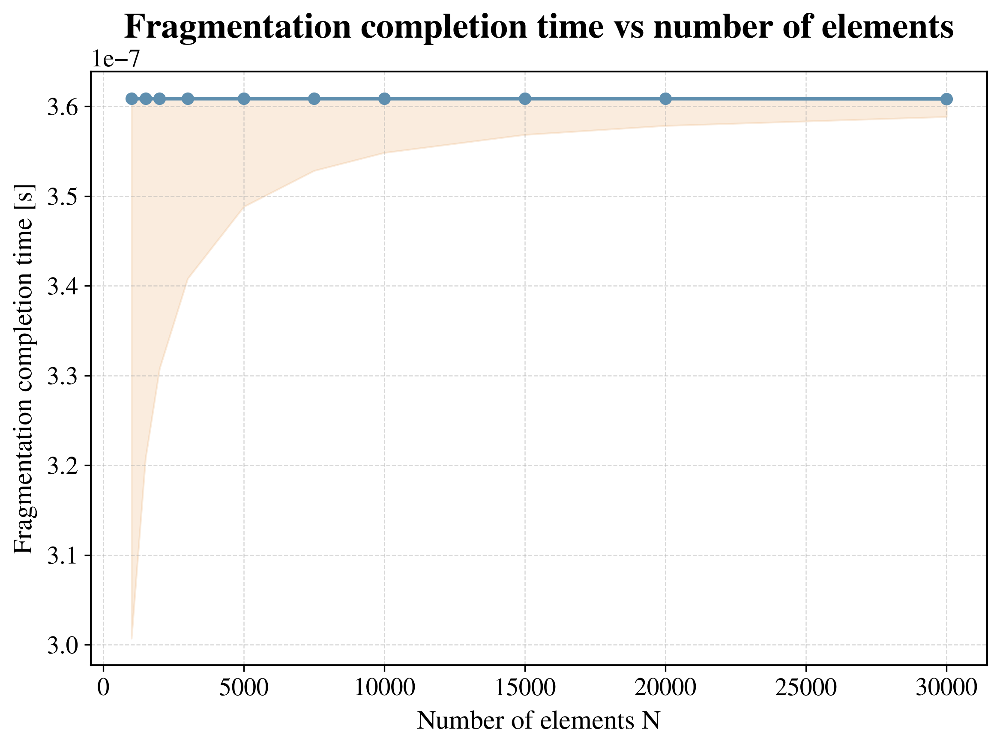

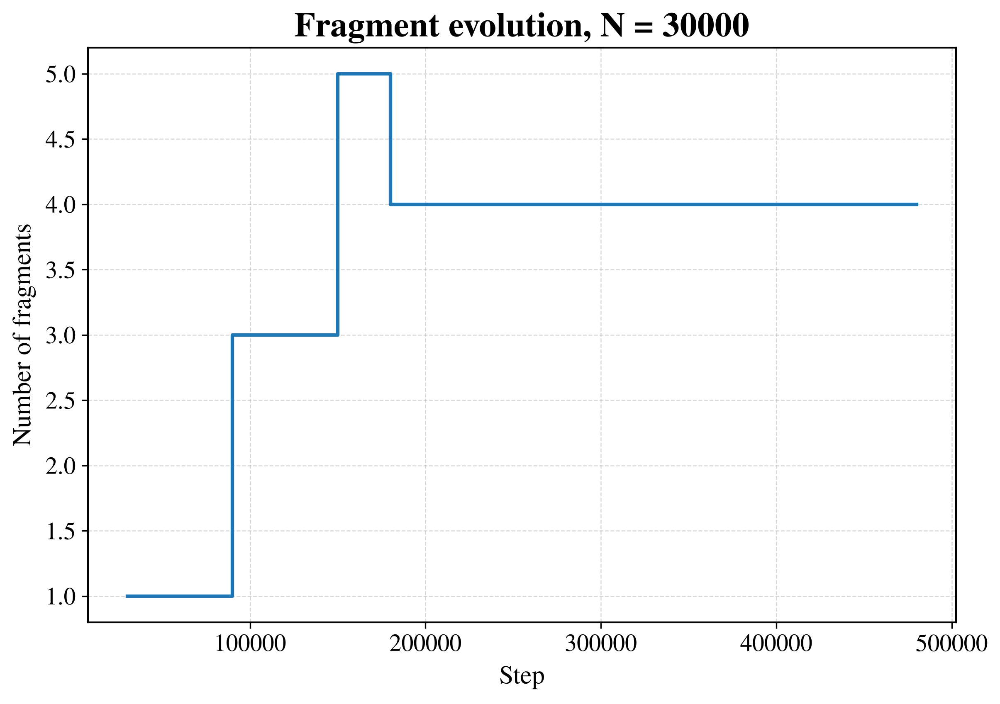

In [18]:
Ns = [1000, 1500, 2000, 3000, 5000, 7500,
      10000, 15000, 20000, 30000, 
      #50000, 75000, 
      #100000, 125000, 150000, 200000
      ]
path = Path("data/PF/mesh_convergence/")
plot_energy_evolution(path, 30000)
plot_fragment_distribution(path, 30000)
plot_velocity_distribution(path, 30000)

plot_fragment_number_vs_N(path, Ns)
plot_simulation_time(path, Ns)

plot_fragment_number_evolution(path, 30000)

---
## <center> Spatial resolution convergence for Peridynamics 

In [21]:
#plotters
# ============================================================================ #
def get_pd_run_path(path, m):
    return path / f"m_{m}"


# ============================================================================ #
def plot_energy_evolution(path, m):
    run_path = get_pd_run_path(path, m)
    data = read_output_file(run_path / "results.out")

    time = data["time"] * 1e6

    total_energy = (
        data["kinetic"]
        + data["strain_energy"]
        + data["dissipated"]
    )

    conserved_energy = total_energy - data["external_work"]

    plt.figure()

    plt.plot(
        time,
        data["kinetic"],
        label="Kinetic",
        color=COLORS["blue"],
    )

    plt.plot(
        time,
        data["strain_energy"],
        label="Strain",
        color=COLORS["orange"],
    )

    plt.plot(
        time,
        data["dissipated"],
        label="Dissipated",
        color=COLORS["red"],
    )

    plt.plot(
        time,
        total_energy,
        label="Total",
        color="black",
    )

    plt.plot(
        time,
        conserved_energy,
        label=r"$E_{\mathrm{tot}}-W_{\mathrm{ext}}$",
        color="gray",
        linestyle="--",
    )

    plt.xlabel(r"Time [$\mu$s]")
    plt.ylabel("Energy [J]")
    plt.title(f"Energy evolution, m = {m}")
    plt.legend()

    plt.show()


# ============================================================================ #
def plot_fragment_number_vs_m(path, m_values):
    fragment_numbers = []

    for m in m_values:
        run_path = get_pd_run_path(path, m)
        data = read_output_file(run_path / "results.out")

        fragment_numbers.append(
            data["num_fragments"].iloc[-1]
        )

    plt.figure()

    plt.plot(
        m_values,
        fragment_numbers,
        marker="o",
        color=COLORS["blue"],
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Final number of fragments")
    plt.title("Fragment number convergence")

    plt.show()


# ============================================================================ #
def plot_energy_error_vs_m(path, m_values):
    errors = []

    for m in m_values:
        log_path = get_pd_run_path(path, m) / "run.log"

        error = None

        with open(log_path) as file:
            for line in file:
                if line.startswith("Energy error:"):
                    error = float(line.split(":")[1])

        errors.append(error)

    plt.figure()

    plt.plot(
        m_values,
        errors,
        marker="o",
        color=COLORS["blue"],
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Energy error")
    plt.title("Energy-error convergence")

    plt.show()


# ============================================================================ #
def plot_wall_time_vs_m(path, m_values):
    times = []

    for m in m_values:
        log_path = get_pd_run_path(path, m) / "run.log"

        wall_time = None

        with open(log_path) as file:
            for line in file:
                if line.startswith("Wall time:"):
                    wall_time = float(line.split()[2])

        times.append(wall_time)

    plt.figure()

    plt.plot(
        m_values,
        times,
        marker="o",
        color=COLORS["blue"],
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Wall time [s]")
    plt.title("Computational cost")

    plt.show()

def plot_fragment_distribution(path, m):
    run_path = path / f"m_{m}"
    fragments = read_output_file(run_path / "fragments.out")

    final_time = fragments["time"].max()

    fragments = fragments[
        np.isclose(fragments["time"], final_time)
    ]

    sizes = fragments["size"]

    plt.figure()

    plt.hist(
        sizes,
        bins="auto",
        edgecolor="black",
        color=COLORS["blue"],
    )

    plt.axvline(
        sizes.mean(),
        linestyle="--",
        color=COLORS["red"],
        label=f"Mean = {sizes.mean():.3e} m",
    )

    plt.xlabel("Fragment size [m]")
    plt.ylabel("Number of fragments")
    plt.title(f"Final fragment-size distribution, m = {m}")
    plt.legend()

    plt.show()

# ============================================================================ #
def plot_fragment_ecdf(path, m_values):
    plt.figure()

    for m in m_values:
        run_path = path / f"m_{m}"
        fragments = read_output_file(run_path / "fragments.out")

        final_time = fragments["time"].max()
        final = fragments[
            np.isclose(fragments["time"], final_time)
        ]

        sizes = np.sort(final["size"].to_numpy())
        cumulative = np.arange(1, len(sizes) + 1) / len(sizes)

        plt.step(
            sizes,
            cumulative,
            where="post",
            label=f"m = {m}",
        )

    plt.xlabel("Fragment size [m]")
    plt.ylabel("Cumulative fraction")
    plt.title("Final fragment-size distributions")
    plt.legend()
    plt.show()

# ============================================================================ #
# ============================================================================ #
def plot_fragment_distributions(path, m_values):
    all_sizes = {}

    # Read final fragment sizes for every m
    for m in m_values:
        run_path = path / f"m_{m}"
        fragments = read_output_file(run_path / "fragments.out")

        final_time = fragments["time"].max()
        final = fragments[
            np.isclose(fragments["time"], final_time)
        ]

        all_sizes[m] = final["size"].to_numpy() * 1e6  # µm

    # Common bins for all distributions
    combined = np.concatenate(list(all_sizes.values()))
    bins = np.histogram_bin_edges(combined, bins="auto")

    plt.figure()

    for m, sizes in all_sizes.items():
        plt.hist(
            sizes,
            bins=bins,
            histtype="step",
            linewidth=2,
            label=f"m = {m}",
        )

    plt.xlabel(r"Fragment size [$\mu$m]")
    plt.ylabel("Number of fragments")
    plt.title("Final fragment-size distributions")
    plt.legend()

    plt.show()

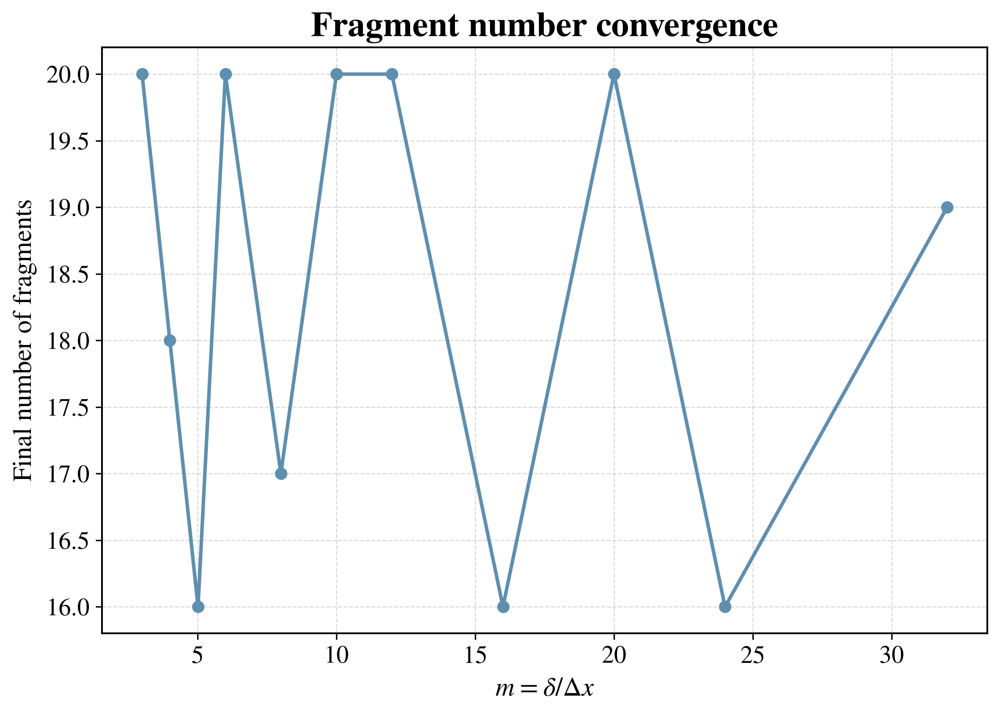

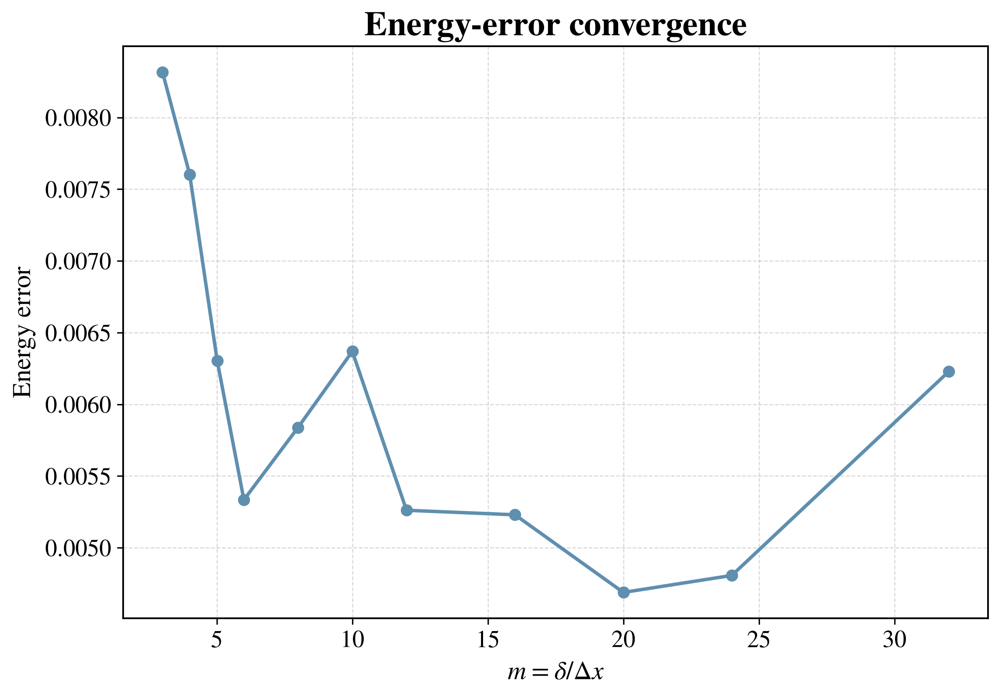

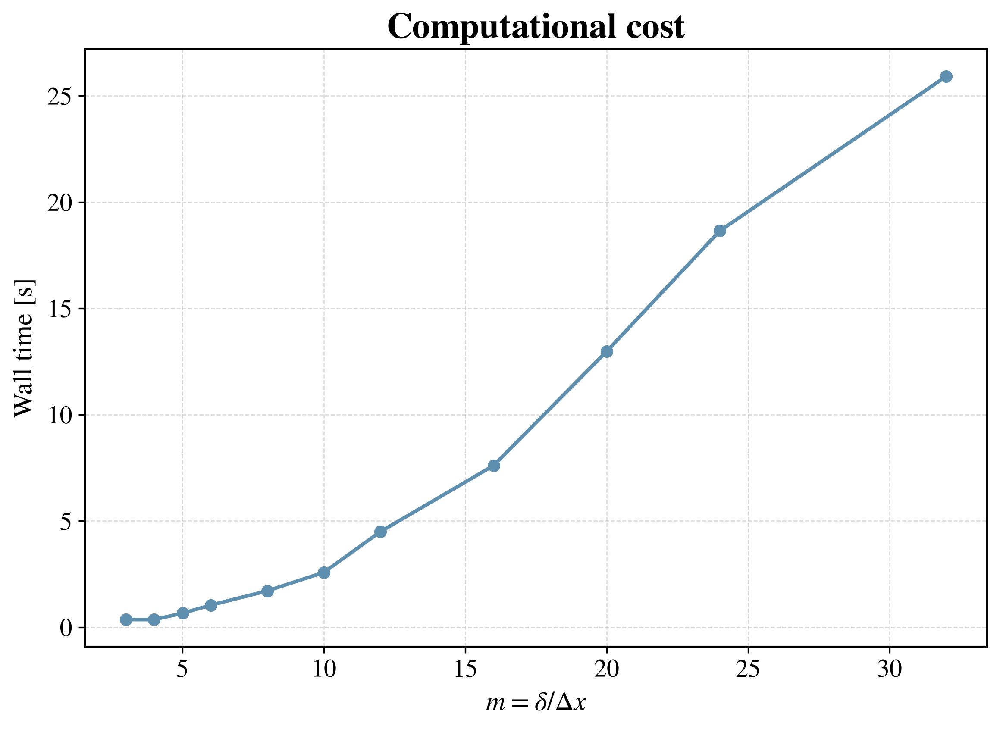

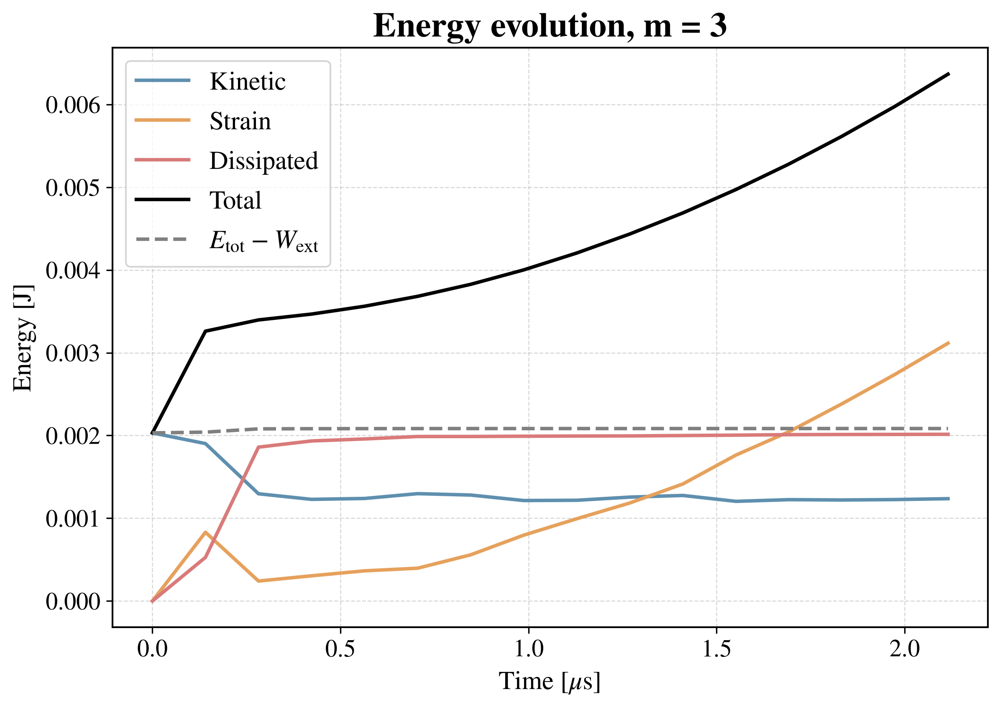

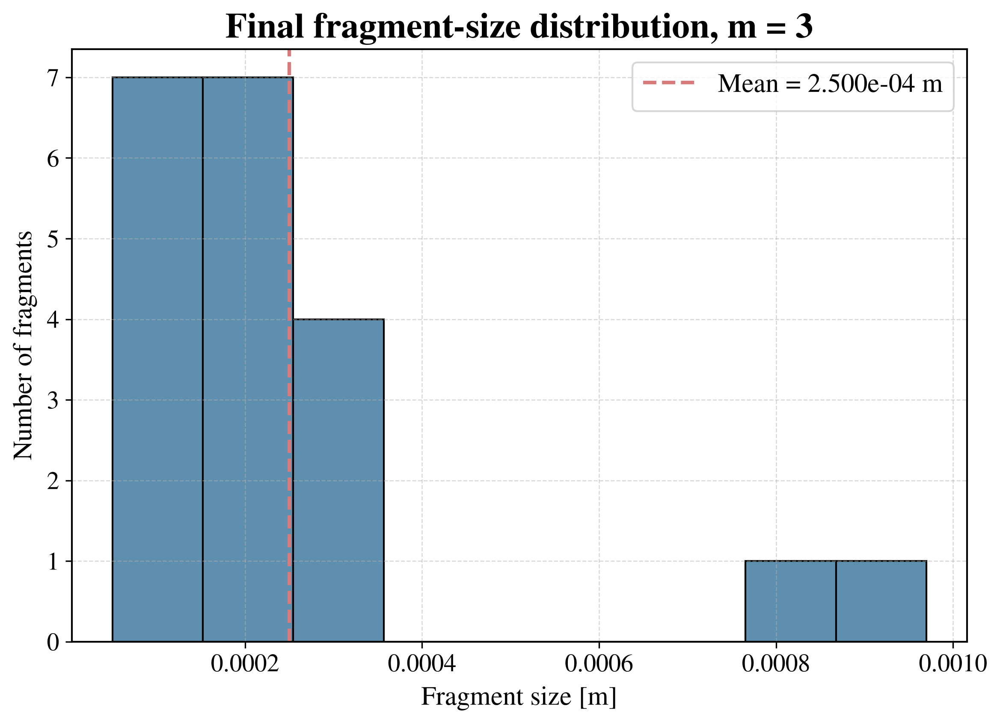

...

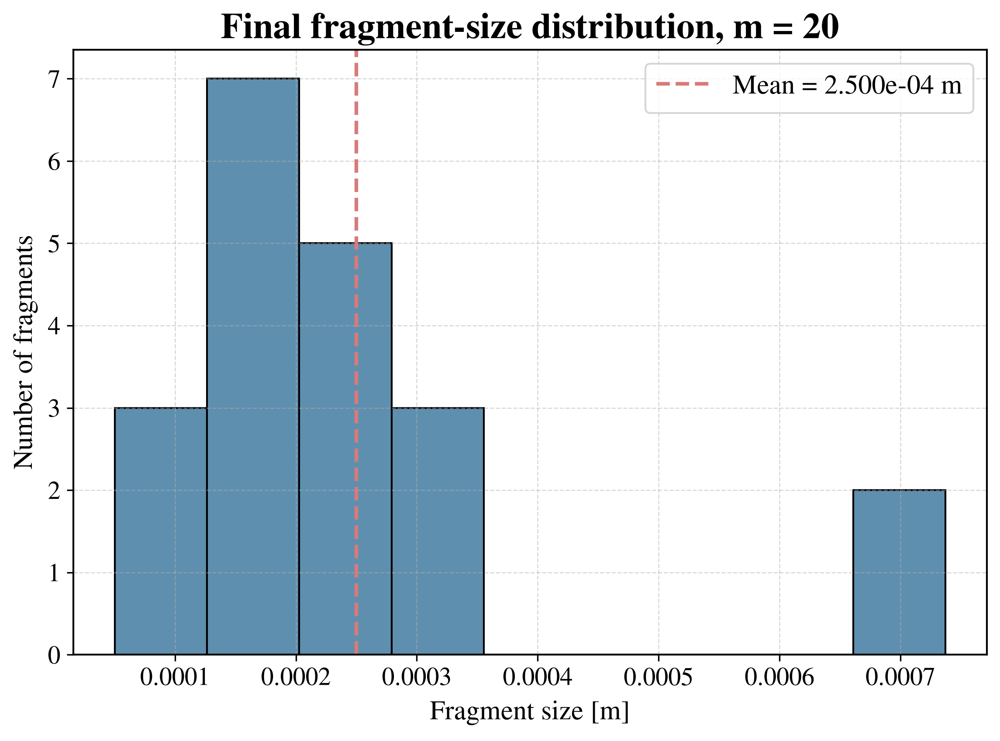

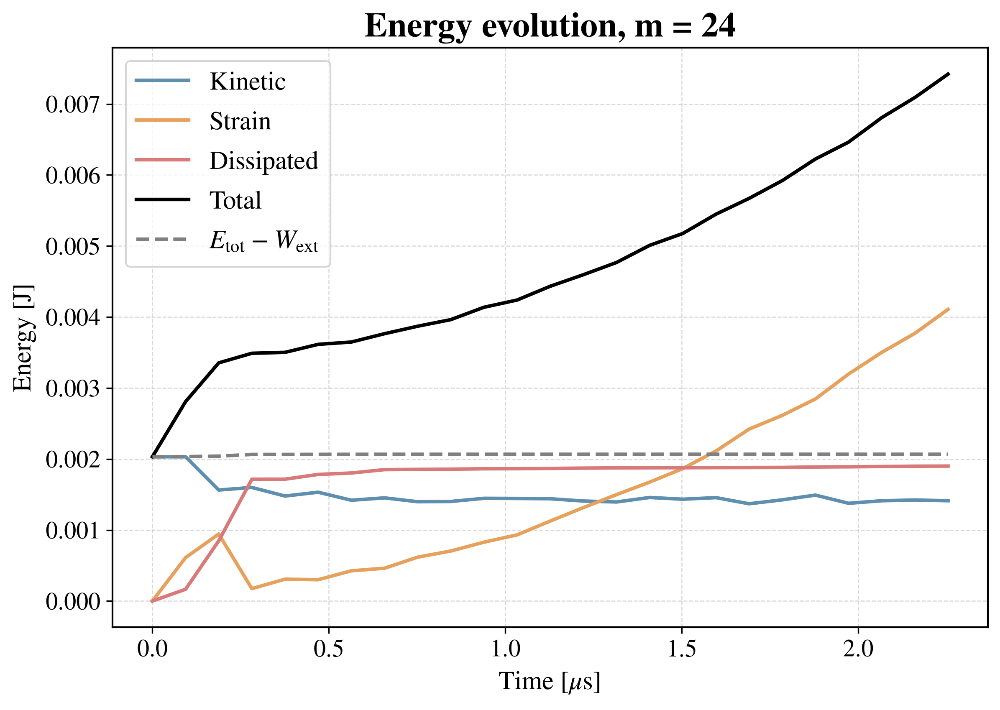

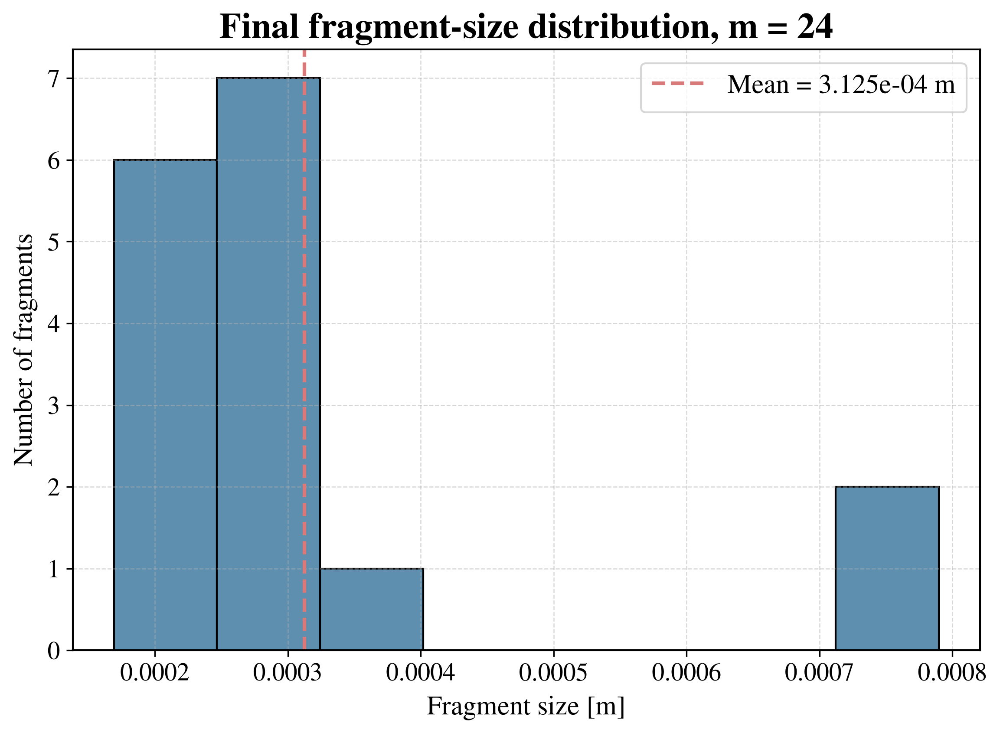

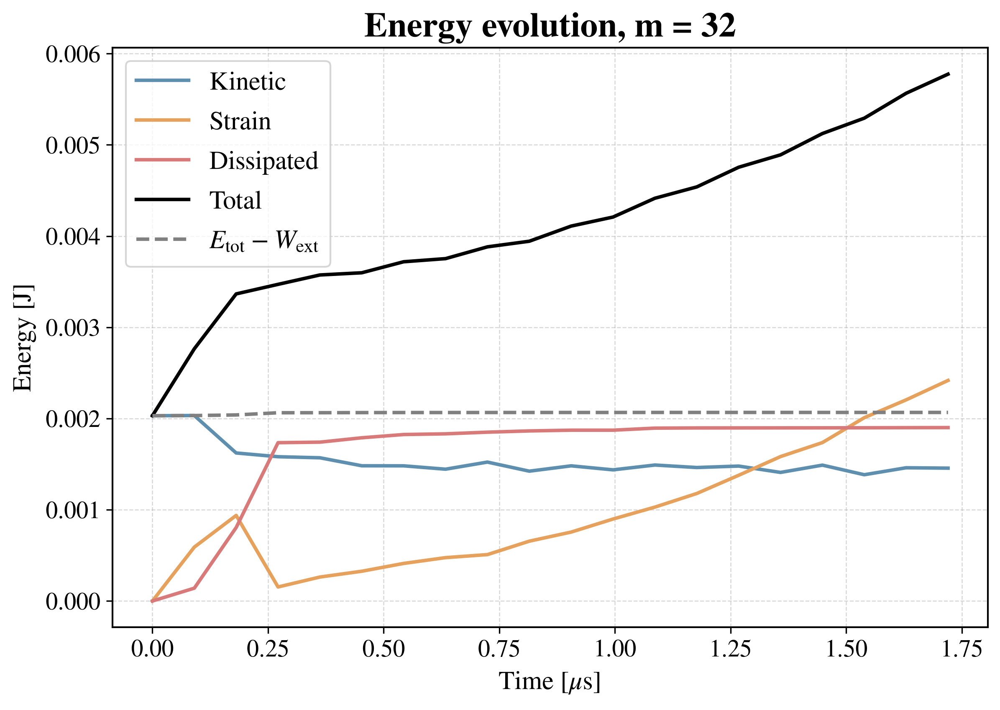

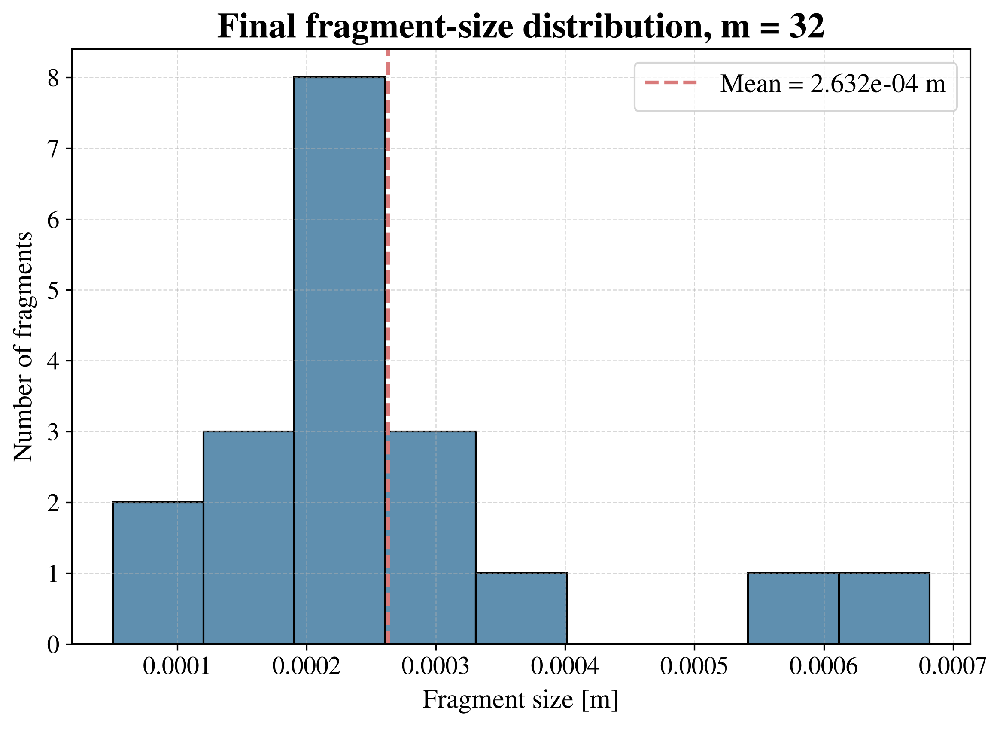

In [ ]:
path = Path("data/PD/convergence_m")
ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32]
plot_fragment_number_vs_m(path, ms)
plot_energy_error_vs_m(path, ms)
plot_wall_time_vs_m(path, ms)

for m in ms:
    plot_energy_evolution(path, m)
    plot_fragment_distribution(path, m)

In [23]:
def fragment_statistics(path, m_values):
    rows = []

    for m in m_values:
        run_path = path / f"m_{m}"
        fragments = read_output_file(run_path / "fragments.out")

        final_time = fragments["time"].max()
        final = fragments[
            np.isclose(fragments["time"], final_time)
        ]

        sizes = final["size"].to_numpy()

        rows.append({
            "m": m,
            "n_fragments": len(sizes),
            "median": np.median(sizes),
            "std": np.std(sizes),
            "min": np.min(sizes),
            "q25": np.percentile(sizes, 25),
            "q75": np.percentile(sizes, 75),
            "max": np.max(sizes),
        })

    return pd.DataFrame(rows)

stats = fragment_statistics(path, ms)
stats

,m,n_fragments,median,std,min,q25,q75,max
0,3.000,14,0.000368,0.000106,0.000167,0.000301,0.000426,0.000535
1,4.000,11,0.000439,0.000177,0.000188,0.000345,0.000533,0.000827
2,5.015,15,0.000320,0.000095,0.000180,0.000265,0.000395,0.000520
3,6.000,15,0.000301,0.000126,0.000167,0.000247,0.000368,0.000669
4,8.000,15,0.000351,0.000084,0.000169,0.000279,0.000401,0.000445
5,10.000,13,0.000371,0.000136,0.000186,0.000276,0.000446,0.000707
6,12.000,14,0.000368,0.000108,0.000100,0.000298,0.000429,0.000573
7,16.000,13,0.000386,0.000180,0.000103,0.000270,0.000486,0.000793
8,20.000,13,0.000371,0.000136,0.000165,0.000298,0.000484,0.000614
9,24.000,14,0.000363,0.000092,0.000198,0.000276,0.000420,0.000516


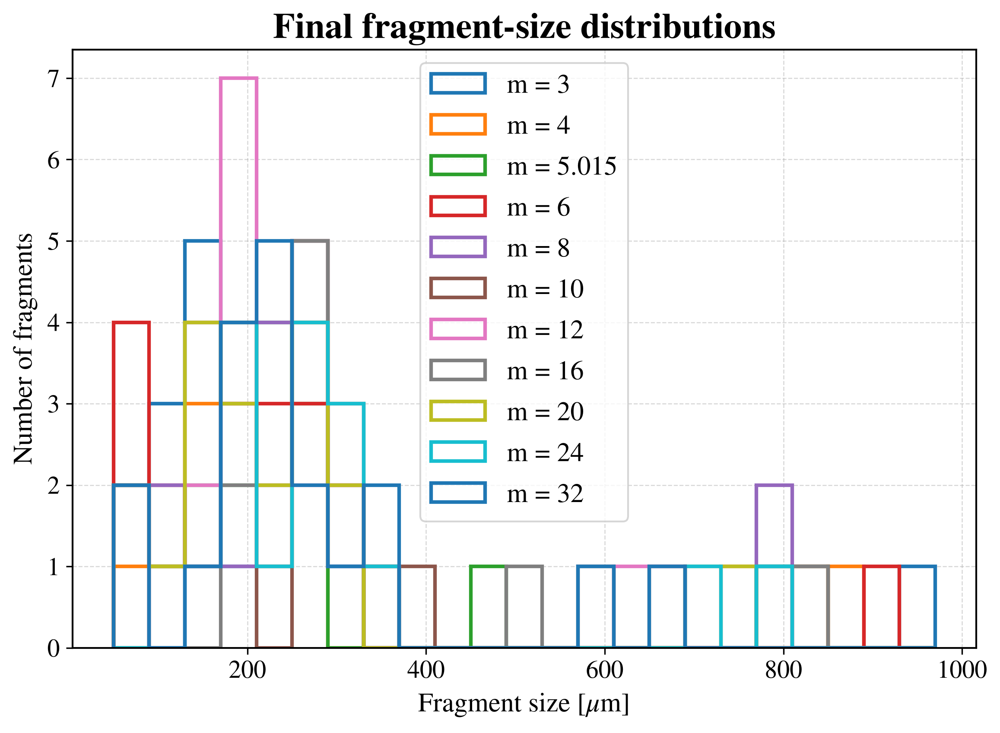

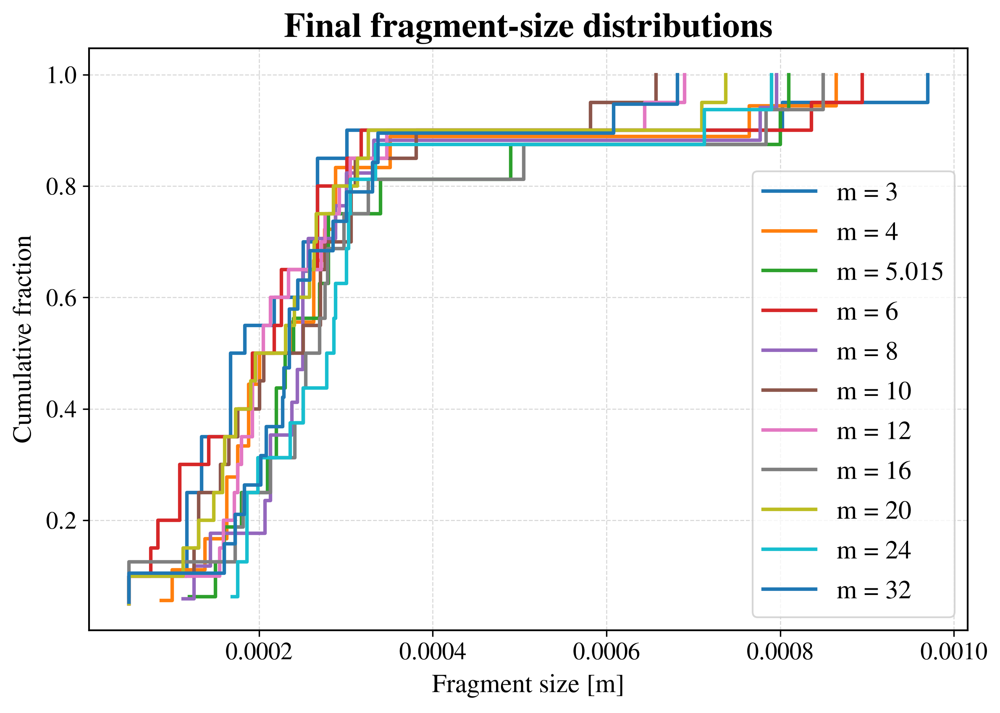

In [ ]:
plot_fragment_distributions(Path("data/PD/convergence_m"), ms,)
plot_fragment_ecdf(Path("data/PD/convergence_m"), ms,)

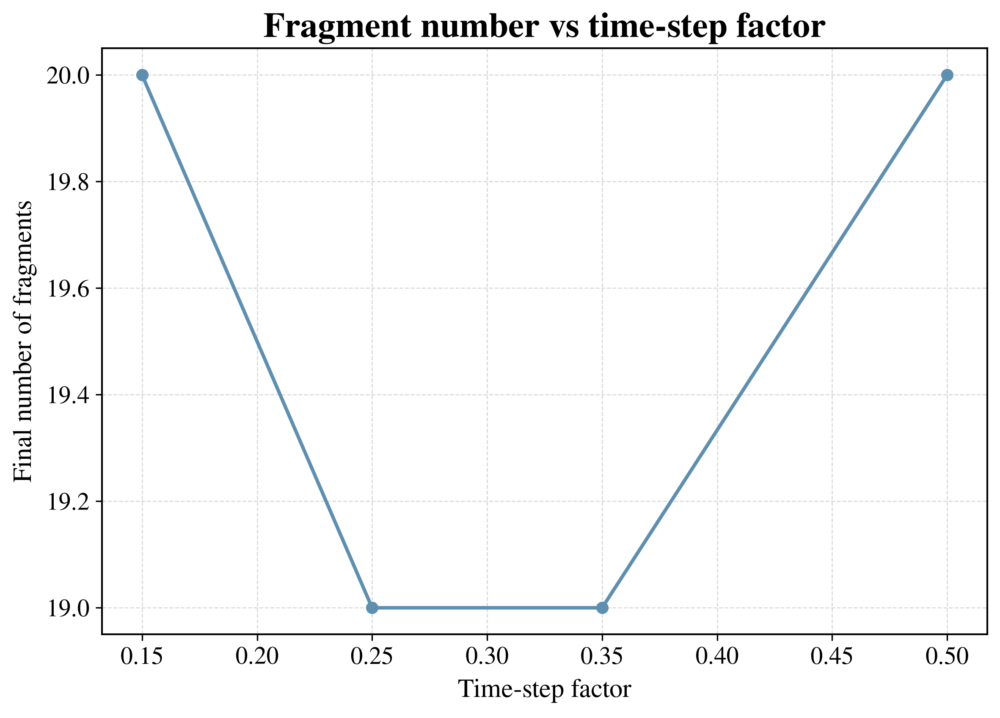

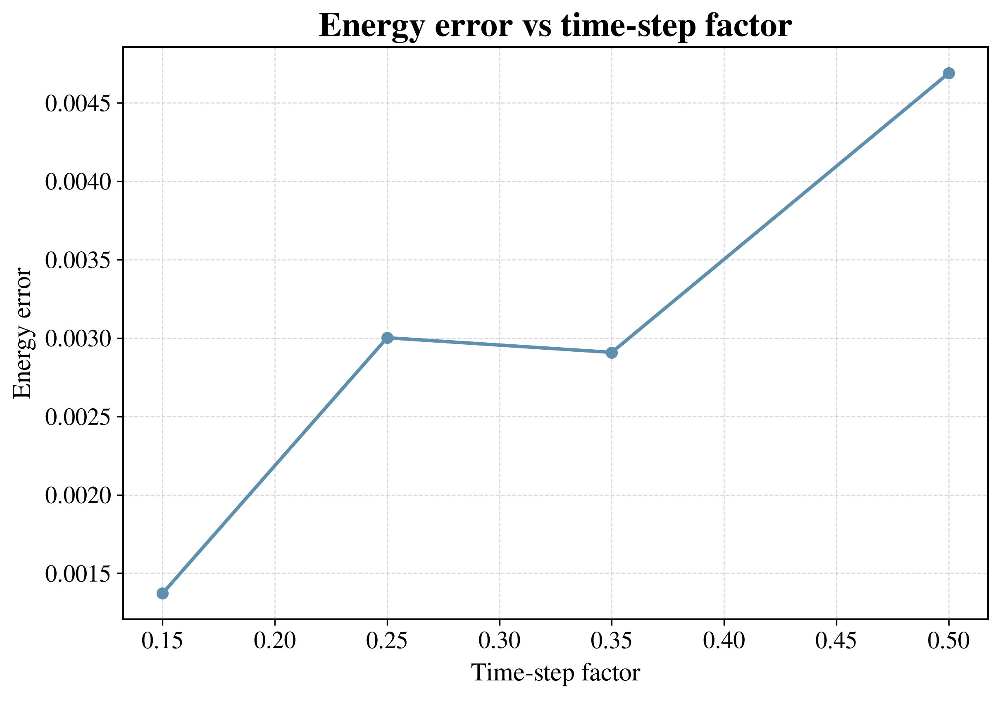

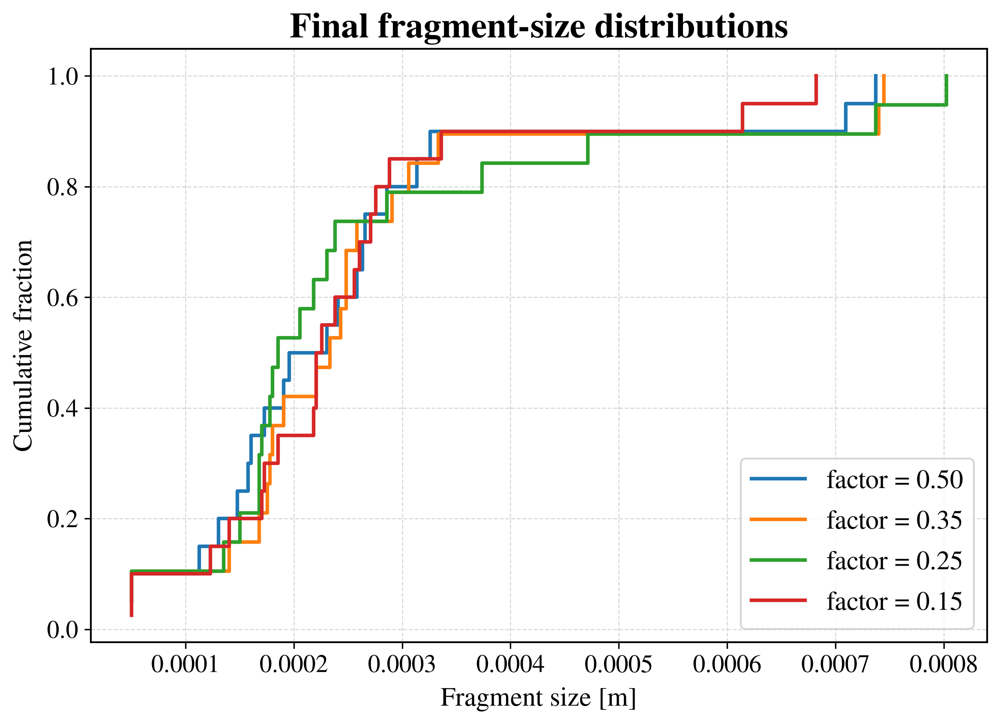

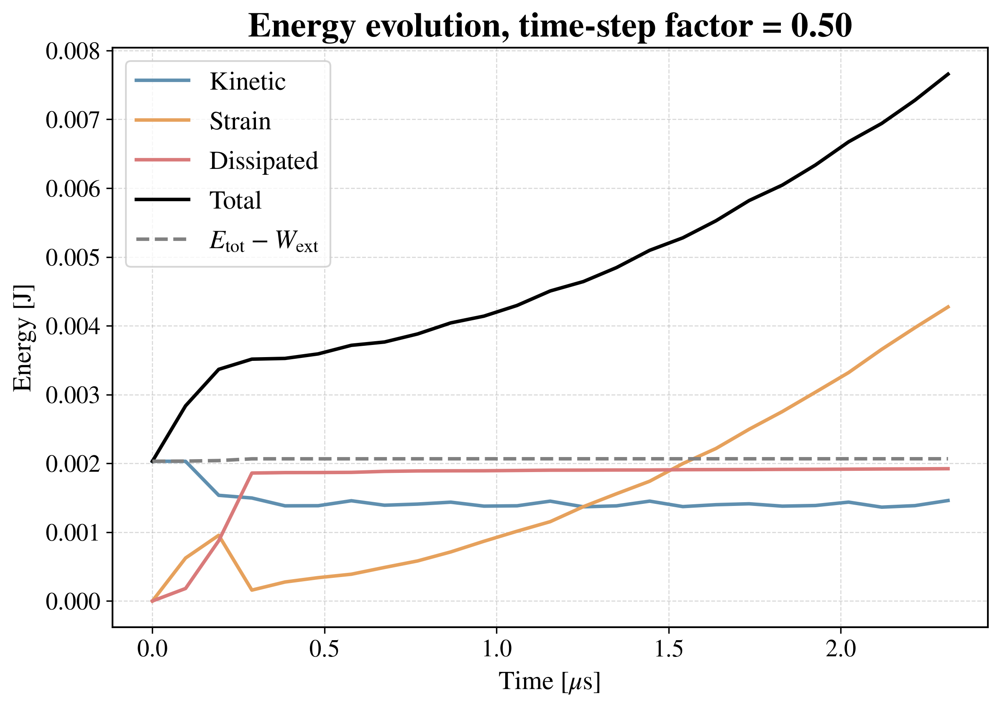

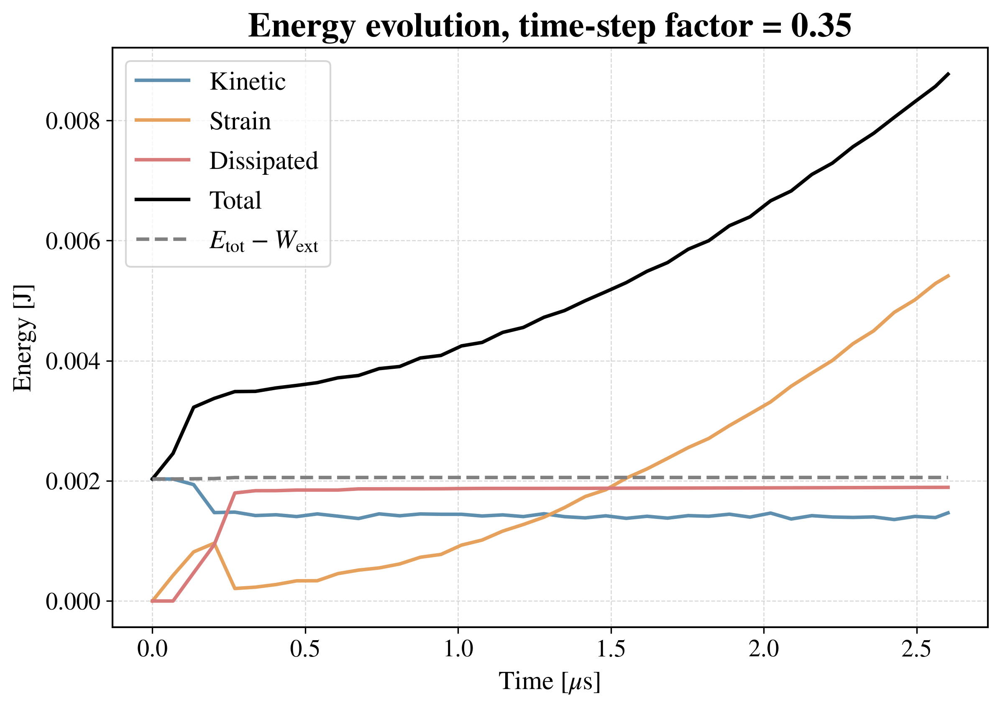

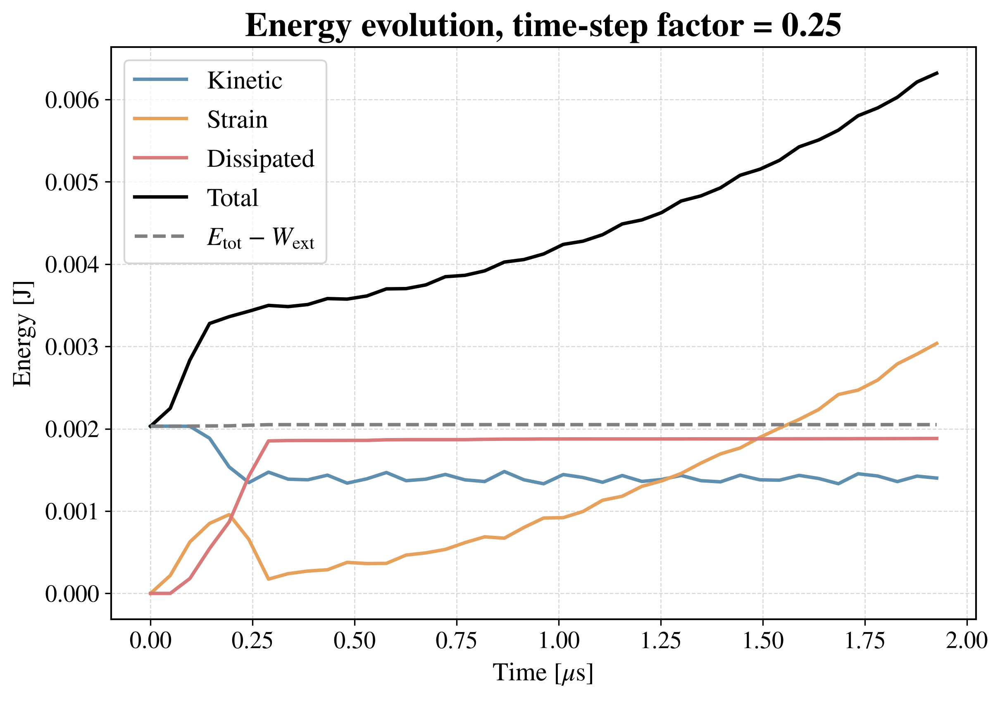

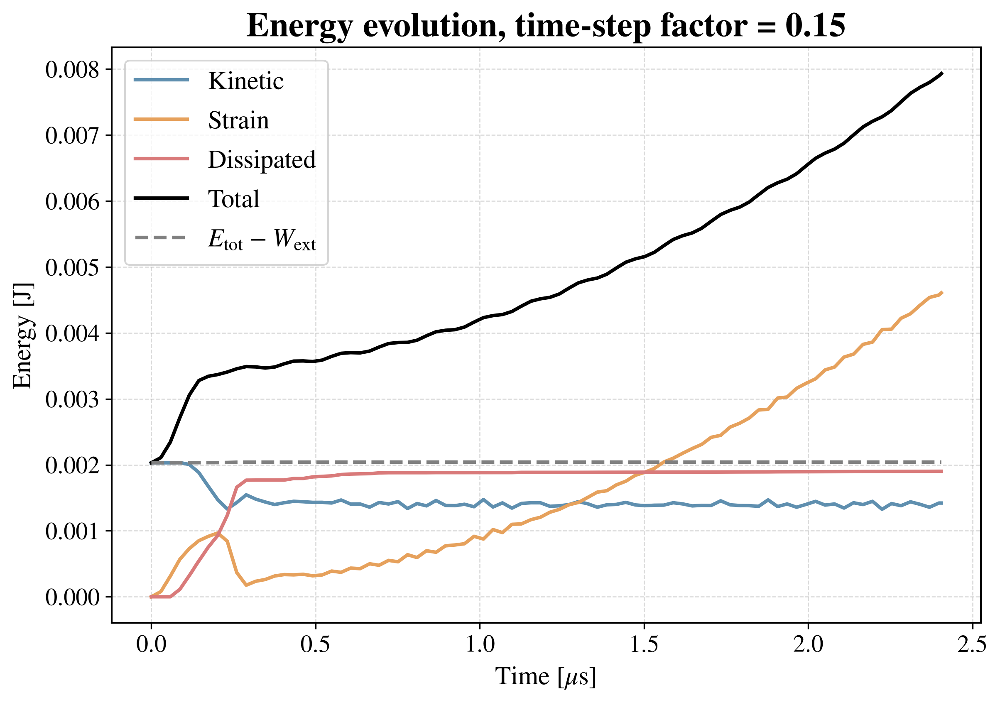

In [ ]:
#plotters
# ============================================================================ #
def get_pd_dt_run_path(path, factor):
    return path / f"dtfactor_{factor:.2f}"


# ============================================================================ #
def plot_fragment_number_vs_dt(path, factors):
    fragment_numbers = []

    for factor in factors:
        run_path = get_pd_dt_run_path(path, factor)
        data = read_output_file(run_path / "results.out")

        fragment_numbers.append(
            data["num_fragments"].iloc[-1]
        )

    plt.figure()

    plt.plot(
        factors,
        fragment_numbers,
        marker="o",
        color=COLORS["blue"],
    )

    plt.xlabel("Time-step factor")
    plt.ylabel("Final number of fragments")
    plt.title("Fragment number vs time-step factor")

    plt.show()


# ============================================================================ #
def plot_energy_error_vs_dt(path, factors):
    errors = []

    for factor in factors:
        run_path = get_pd_dt_run_path(path, factor)
        log_path = run_path / "run.log"

        error = None

        with open(log_path) as file:
            for line in file:
                if line.startswith("Energy error:"):
                    error = float(line.split(":")[1])

        errors.append(error)

    plt.figure()

    plt.plot(
        factors,
        errors,
        marker="o",
        color=COLORS["blue"],
    )

    plt.xlabel("Time-step factor")
    plt.ylabel("Energy error")
    plt.title("Energy error vs time-step factor")

    plt.show()


# ============================================================================ #
def plot_fragment_distributions_dt(path, factors):
    plt.figure()

    for factor in factors:
        run_path = get_pd_dt_run_path(path, factor)

        fragments = read_output_file(
            run_path / "fragments.out"
        )

        final_time = fragments["time"].max()

        final = fragments[
            np.isclose(
                fragments["time"],
                final_time,
            )
        ]

        sizes = np.sort(
            final["size"].to_numpy()
        )

        cumulative = (
            np.arange(1, len(sizes) + 1)
            / len(sizes)
        )

        plt.step(
            sizes,
            cumulative,
            where="post",
            label=f"factor = {factor:.2f}",
        )

    plt.xlabel("Fragment size [m]")
    plt.ylabel("Cumulative fraction")
    plt.title("Final fragment-size distributions")
    plt.legend()

    plt.show()


# ============================================================================ #
def plot_energy_evolution_dt(path, factor):
    run_path = get_pd_dt_run_path(path, factor)

    data = read_output_file(
        run_path / "results.out"
    )

    time = data["time"] * 1e6

    total_energy = (
        data["kinetic"]
        + data["strain_energy"]
        + data["dissipated"]
    )

    conserved_energy = (
        total_energy
        - data["external_work"]
    )

    plt.figure()

    plt.plot(
        time,
        data["kinetic"],
        label="Kinetic",
        color=COLORS["blue"],
    )

    plt.plot(
        time,
        data["strain_energy"],
        label="Strain",
        color=COLORS["orange"],
    )

    plt.plot(
        time,
        data["dissipated"],
        label="Dissipated",
        color=COLORS["red"],
    )

    plt.plot(
        time,
        total_energy,
        label="Total",
        color="black",
    )

    plt.plot(
        time,
        conserved_energy,
        label=r"$E_{\mathrm{tot}}-W_{\mathrm{ext}}$",
        color="gray",
        linestyle="--",
    )

    plt.xlabel(r"Time [$\mu$s]")
    plt.ylabel("Energy [J]")

    plt.title(
        f"Energy evolution, "
        f"time-step factor = {factor:.2f}"
    )

    plt.legend()
    plt.show()


# ============================================================================ #
path_dt = Path("data/PD/convergence_dt")

factors = [0.50, 0.35, 0.25, 0.15]

plot_fragment_number_vs_dt(
    path_dt,
    factors,
)

plot_energy_error_vs_dt(
    path_dt,
    factors,
)

plot_fragment_distributions_dt(
    path_dt,
    factors,
)

for factor in factors:
    plot_energy_evolution_dt(
        path_dt,
        factor,
    )

In [7]:
#plotters
# ============================================================================ #
def read_pd_calibration(path, m_values):
    rows = []

    keys = [
        "E_as_built",
        "stiffness_scale",
        "cut_sum",
        "mean_s_elastic",
        "mean_s_break",
        "dt_max",
        "dt",
        "dx_calibration",
        "horizon_calibration",
        "m_calibration",
    ]

    for m in m_values:
        run_path = path / f"m_{m}" / "run.log"

        values = {}

        with open(run_path, "r") as f:
            for line in f:
                for key in keys:
                    if line.startswith(key + ":"):
                        values[key] = float(
                            line.split(":", 1)[1].strip()
                        )

        rows.append({
            "m_target": m,
            **values,
        })

    return pd.DataFrame(rows)

# ============================================================================ #
def plot_stiffness_calibration(data):
    plt.figure()

    plt.plot(
        data["m_calibration"],
        data["stiffness_scale"],
        marker="o",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Stiffness scale")
    plt.title("PD stiffness calibration")

    plt.show()

# ============================================================================ #
def plot_E_as_built(data):
    plt.figure()

    plt.plot(
        data["m_calibration"],
        data["E_as_built"] / 1e9,
        marker="o",
    )

    plt.axhline(
        370,
        linestyle="--",
        label="Target E",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel(r"$E_{\mathrm{as-built}}$ [GPa]")
    plt.title("Uncorrected elastic stiffness")
    plt.legend()

    plt.show()

# ============================================================================ #
def plot_cut_sum(data):
    plt.figure()

    plt.plot(
        data["m_calibration"],
        data["cut_sum"],
        marker="o",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("cut_sum")
    plt.title("PD fracture-energy calibration")

    plt.show()

# ============================================================================ #
def plot_failure_stretches(data):
    plt.figure()

    plt.plot(
        data["m_calibration"],
        data["mean_s_elastic"],
        marker="o",
        label=r"$s_{\mathrm{elastic}}$",
    )

    plt.plot(
        data["m_calibration"],
        data["mean_s_break"],
        marker="o",
        label=r"$s_{\mathrm{break}}$",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Mean bond stretch")
    plt.title("Bond-law calibration")
    plt.legend()

    plt.show()

# ============================================================================ #
def plot_dt_vs_m(data):
    plt.figure()

    plt.plot(
        data["m_calibration"],
        data["dt"] * 1e12,
        marker="o",
        label=r"$\Delta t$",
    )

    plt.plot(
        data["m_calibration"],
        data["dt_max"] * 1e12,
        marker="o",
        label=r"$\Delta t_{\max}$",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Time step [ps]")
    plt.title("Time-step refinement")
    plt.legend()

    plt.show()

,m_target,E_as_built,stiffness_scale,cut_sum,mean_s_elastic,mean_s_break,dt_max,dt,dx_calibration,horizon_calibration,m_calibration
0,3.000,3.700000e+11,1.00000,6.52914,0.000708,0.010815,2.820380e-09,1.410190e-09,0.000017,0.00005,2.99897
1,4.000,3.700000e+11,1.00000,6.37816,0.000708,0.011071,2.601290e-09,1.300650e-09,0.000013,0.00005,4.00197
2,5.015,3.699970e+11,1.00001,6.30765,0.000708,0.011194,2.462220e-09,1.231110e-09,0.000010,0.00005,5.01500
3,6.000,3.700000e+11,1.00000,6.27116,0.000708,0.011260,2.366740e-09,1.183370e-09,0.000008,0.00005,5.99794
4,8.000,3.700000e+11,1.00000,6.23341,0.000708,0.011328,2.234010e-09,1.117010e-09,0.000006,0.00005,8.00394
5,10.000,3.700000e+11,1.00000,6.21609,0.000708,0.011359,2.145700e-09,1.072850e-09,0.000005,0.00005,9.99991
6,12.000,3.700000e+11,1.00000,6.20666,0.000708,0.011377,2.080850e-09,1.040430e-09,0.000004,0.00005,11.99590
7,16.000,3.700000e+11,1.00000,6.19725,0.000708,0.011394,1.989330e-09,9.946660e-10,0.000003,0.00005,15.99780
8,20.000,3.700000e+11,1.00000,6.19290,0.000708,0.011402,1.926140e-09,9.630690e-10,0.000003,0.00005,19.99980
9,24.000,3.700000e+11,1.00000,6.19053,0.000708,0.011406,1.878760e-09,9.393790e-10,0.000002,0.00005,24.00180


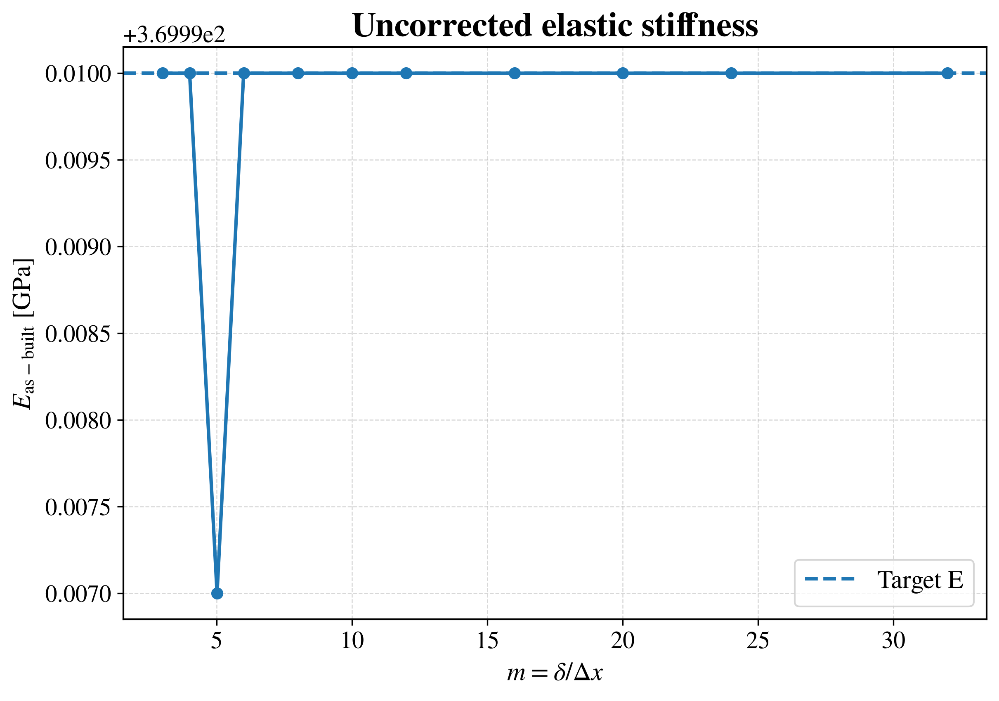

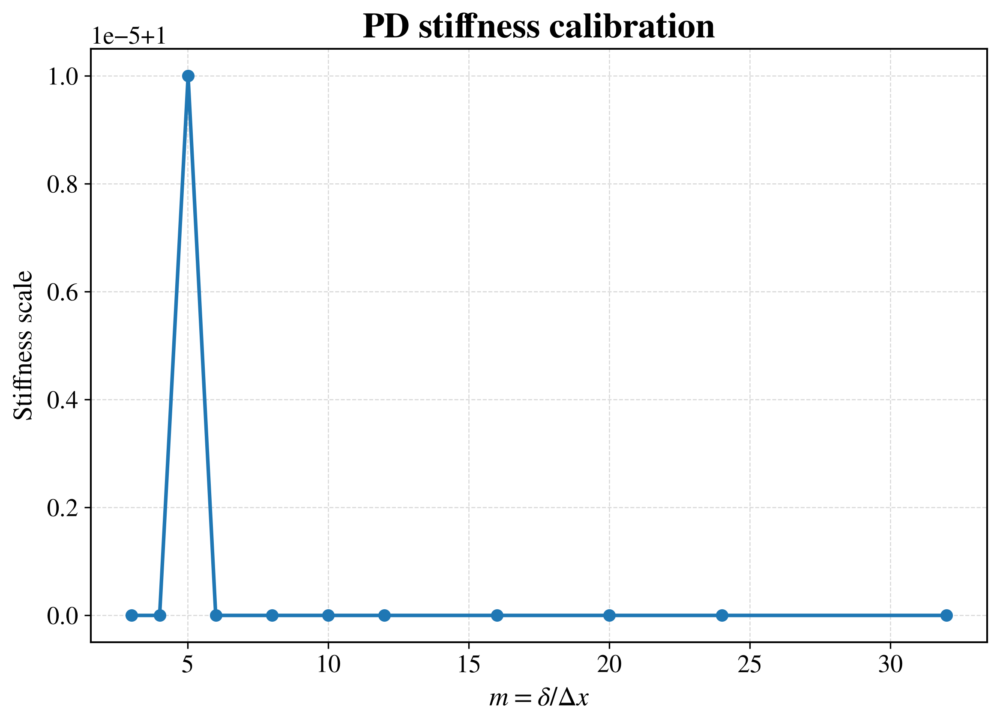

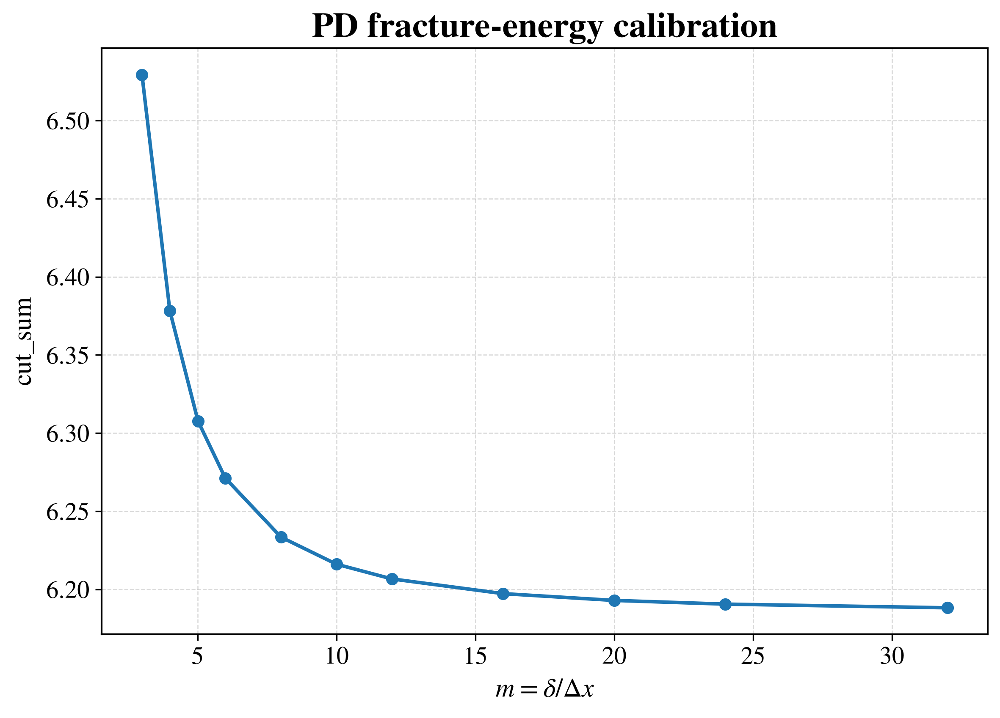

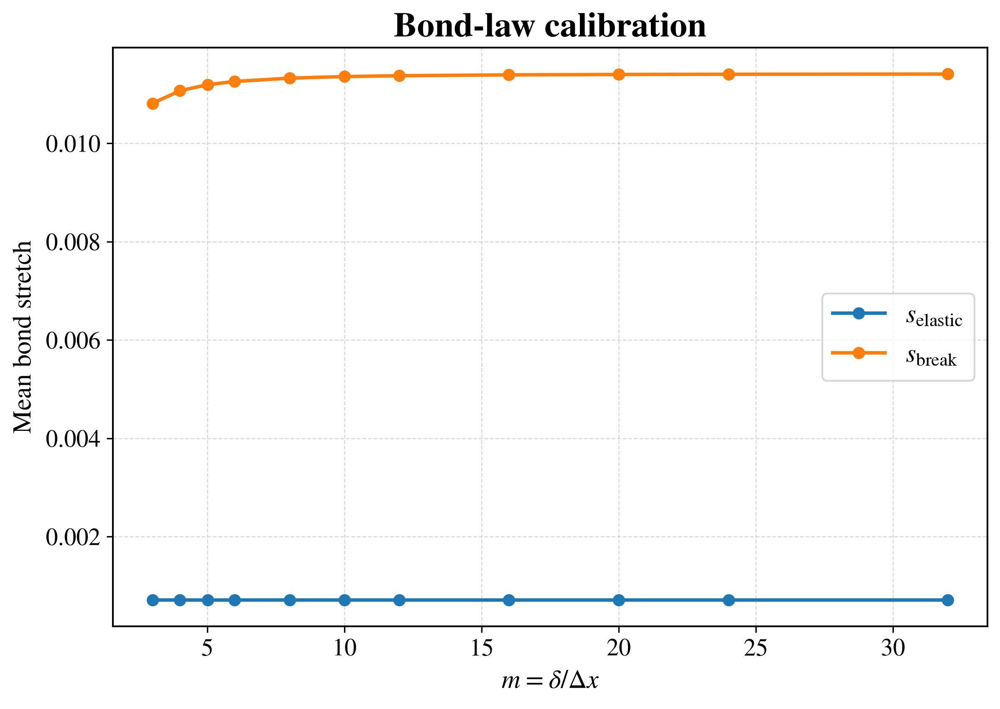

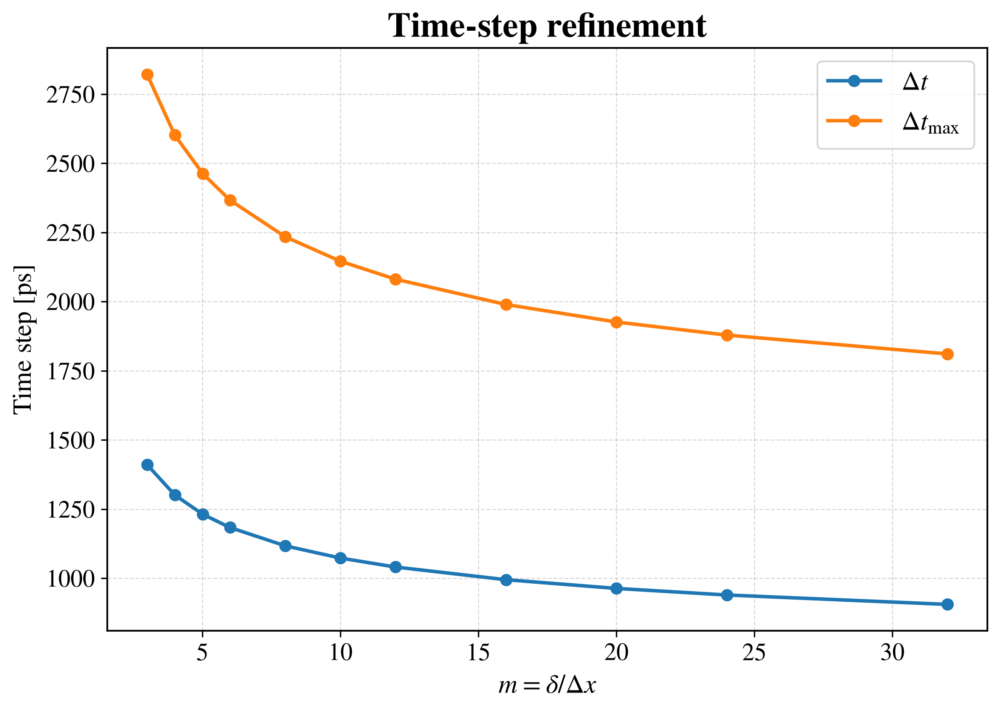

In [8]:
path = Path("data/PD/convergence_m")

ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32]

calibration = read_pd_calibration(path, ms)

display(calibration)

plot_E_as_built(calibration)
plot_stiffness_calibration(calibration)
plot_cut_sum(calibration)
plot_failure_stretches(calibration)
plot_dt_vs_m(calibration)

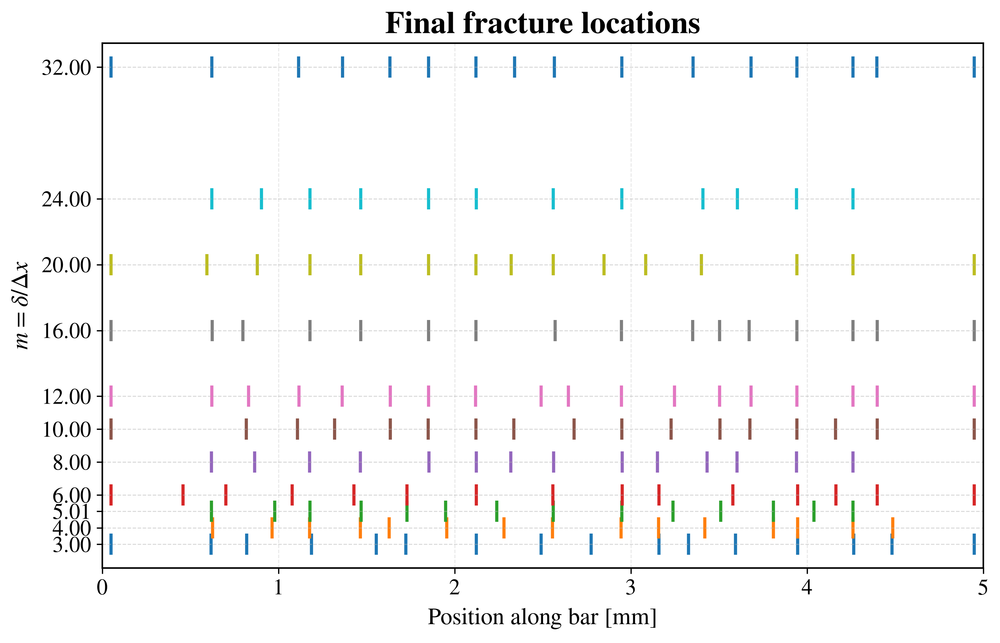

In [ ]:
def plot_fracture_locations(path, m_values):
    plt.figure(figsize=(10, 6))

    for m in m_values:
        run_path = path / f"m_{m}"

        fragments = read_output_file(
            run_path / "fragments.out"
        )

        # Final snapshot
        final_time = fragments["time"].max()
        final = fragments[
            np.isclose(fragments["time"], final_time)
        ].sort_values("fragment_id")

        # x_left of every fragment except the first
        # corresponds to an internal fracture position
        cuts = final["x_left"].to_numpy()[1:]

        plt.scatter(
            cuts * 1e3,                     # m -> mm
            np.full(len(cuts), m),
            marker="|",
            s=180,
            linewidths=2,
        )

    plt.xlabel("Position along bar [mm]")
    plt.ylabel(r"$m = \delta/\Delta x$")
    plt.title("Final fracture locations")

    plt.yticks(m_values)
    plt.xlim(0, 5)

    plt.grid(axis="x", alpha=0.3)
    plt.show()

path = Path("data/PD/convergence_m")

ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32]

plot_fracture_locations(path, ms)

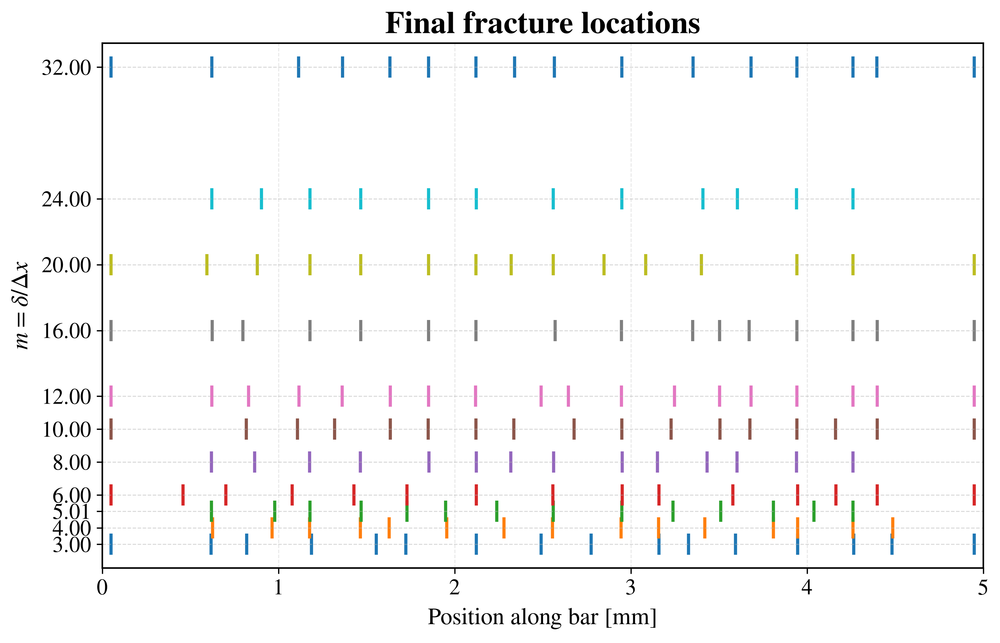

NameError: name 'plot_fragment_distributions' is not defined

In [ ]:
path = Path("data/PD/convergence_m_scatter")

ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32]

plot_fracture_locations(path, ms)

,m,mean_distance,median_distance,max_distance
0,3.000,0.000148,6.984966e-05,0.000689
1,4.000,0.000084,8.613153e-05,0.000237
2,5.015,0.000083,9.753095e-05,0.000232
3,6.000,0.000162,9.720801e-05,0.000689
4,8.000,0.000044,2.095919e-06,0.000231
5,10.000,0.000166,9.893416e-05,0.000689
6,12.000,0.000146,8.232268e-05,0.000689
7,16.000,0.000134,5.703023e-05,0.000689
8,20.000,0.000139,1.359666e-06,0.000689
9,24.000,0.000032,8.159115e-07,0.000234


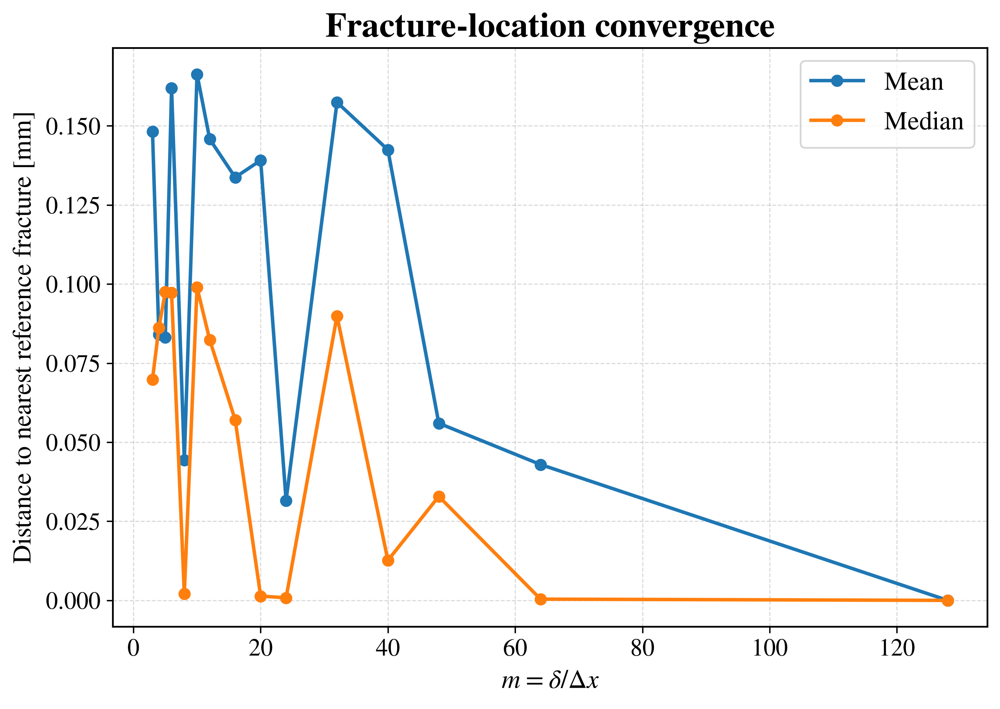

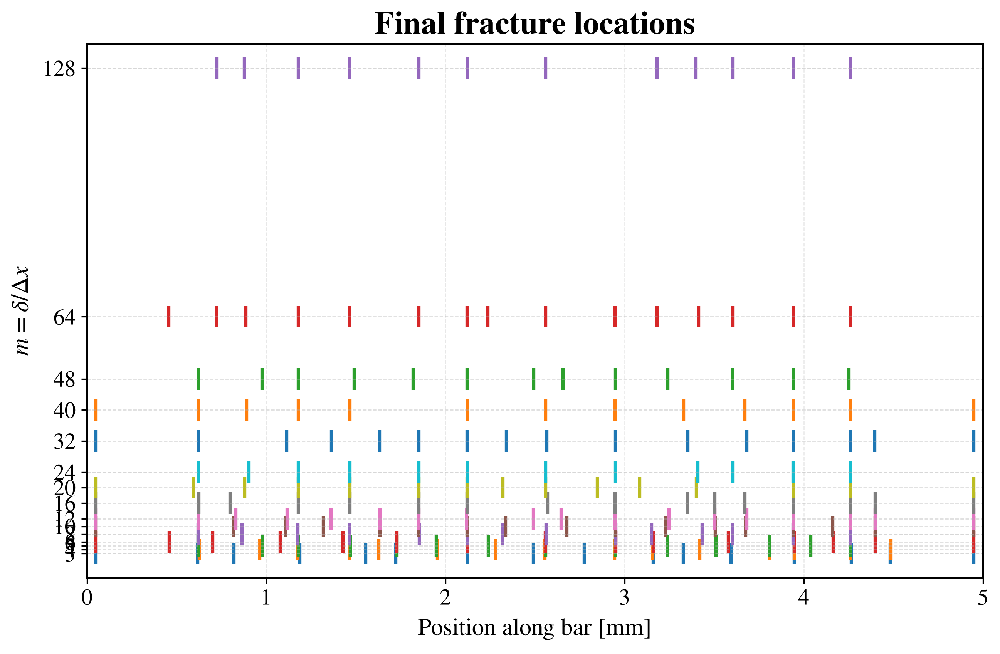

In [17]:
def fracture_location_error(path, m_values, reference_m=32):
    # Reference fracture positions
    ref_path = path / f"m_{reference_m}"
    ref_fragments = read_output_file(ref_path / "fragments.out")

    ref_final_time = ref_fragments["time"].max()
    ref_final = ref_fragments[
        np.isclose(ref_fragments["time"], ref_final_time)
    ].sort_values("fragment_id")

    ref_cuts = ref_final["x_left"].to_numpy()[1:]

    rows = []

    for m in m_values:
        run_path = path / f"m_{m}"
        fragments = read_output_file(run_path / "fragments.out")

        final_time = fragments["time"].max()
        final = fragments[
            np.isclose(fragments["time"], final_time)
        ].sort_values("fragment_id")

        cuts = final["x_left"].to_numpy()[1:]

        nearest_distances = []

        for x in cuts:
            nearest_distances.append(
                np.min(np.abs(ref_cuts - x))
            )

        rows.append({
            "m": m,
            "mean_distance": np.mean(nearest_distances),
            "median_distance": np.median(nearest_distances),
            "max_distance": np.max(nearest_distances),
        })

    return pd.DataFrame(rows)

def plot_fracture_location_error(data):
    plt.figure()

    plt.plot(
        data["m"],
        data["mean_distance"] * 1e3,
        marker="o",
        label="Mean",
    )

    plt.plot(
        data["m"],
        data["median_distance"] * 1e3,
        marker="o",
        label="Median",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Distance to nearest reference fracture [mm]")
    plt.title("Fracture-location convergence")
    plt.legend()

    plt.show()

path = Path("data/PD/convergence_m_scatter")

ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64, 128]

location_error = fracture_location_error(
    path,
    ms,
    reference_m=128,
)

display(location_error)

plot_fracture_location_error(location_error)
plot_fracture_locations(path, ms)

,m,mean_symmetric_distance,hausdorff_distance
0,12,0.000099,0.000689
1,16,0.000086,0.000689
2,20,0.000088,0.000689
3,24,0.000031,0.000234
4,32,0.000112,0.000689
5,40,0.000099,0.000689
6,48,0.000051,0.000234
7,64,0.000023,0.000269
8,128,0.000000,0.000000


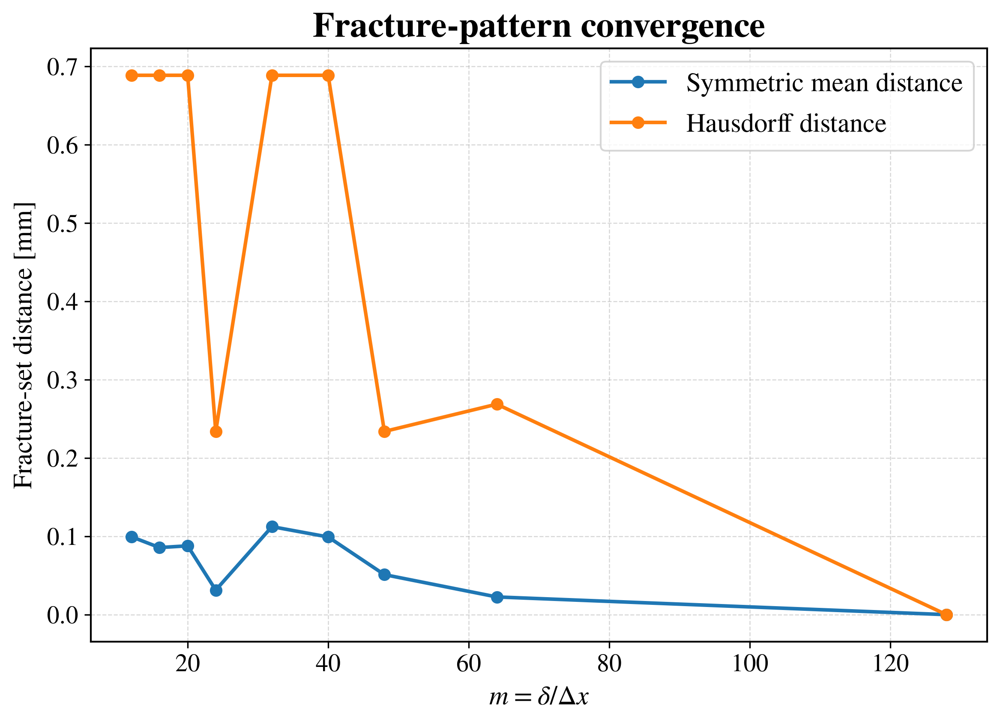

In [18]:
def get_final_cuts(path, m):
    fragments = read_output_file(
        path / f"m_{m}" / "fragments.out"
    )

    final_time = fragments["time"].max()

    final = fragments[
        np.isclose(fragments["time"], final_time)
    ].sort_values("fragment_id")

    return final["x_left"].to_numpy()[1:]

def symmetric_fracture_distance(cuts_a, cuts_b):
    d_a_to_b = np.array([
        np.min(np.abs(cuts_b - x))
        for x in cuts_a
    ])

    d_b_to_a = np.array([
        np.min(np.abs(cuts_a - x))
        for x in cuts_b
    ])

    mean_symmetric = 0.5 * (
        np.mean(d_a_to_b)
        + np.mean(d_b_to_a)
    )

    hausdorff = max(
        np.max(d_a_to_b),
        np.max(d_b_to_a),
    )

    return mean_symmetric, hausdorff
def fracture_set_convergence(path, m_values, reference_m=128):
    ref_cuts = get_final_cuts(path, reference_m)

    rows = []

    for m in m_values:
        cuts = get_final_cuts(path, m)

        mean_distance, hausdorff = symmetric_fracture_distance(
            cuts,
            ref_cuts,
        )

        rows.append({
            "m": m,
            "mean_symmetric_distance": mean_distance,
            "hausdorff_distance": hausdorff,
        })

    return pd.DataFrame(rows)

def plot_fracture_set_convergence(data):
    plt.figure()

    plt.plot(
        data["m"],
        data["mean_symmetric_distance"] * 1e3,
        marker="o",
        label="Symmetric mean distance",
    )

    plt.plot(
        data["m"],
        data["hausdorff_distance"] * 1e3,
        marker="o",
        label="Hausdorff distance",
    )

    plt.xlabel(r"$m = \delta/\Delta x$")
    plt.ylabel("Fracture-set distance [mm]")
    plt.title("Fracture-pattern convergence")
    plt.legend()

    plt.show()

ms = [12, 16, 20, 24, 32, 40, 48, 64, 128]

set_error = fracture_set_convergence(
    path,
    ms,
    reference_m=128,
)

display(set_error)

plot_fracture_set_convergence(set_error)

In [19]:
def successive_fracture_convergence(path, m_values):
    rows = []

    for m1, m2 in zip(m_values[:-1], m_values[1:]):
        cuts1 = get_final_cuts(path, m1)
        cuts2 = get_final_cuts(path, m2)

        mean_distance, hausdorff = symmetric_fracture_distance(
            cuts1,
            cuts2,
        )

        rows.append({
            "m_coarse": m1,
            "m_fine": m2,
            "mean_distance": mean_distance,
            "hausdorff_distance": hausdorff,
        })

    return pd.DataFrame(rows)

ms_high = [32, 40, 48, 64, 128]

successive = successive_fracture_convergence(
    path,
    ms_high,
)

display(successive)

,m_coarse,m_fine,mean_distance,hausdorff_distance
0,32,40,0.000048,0.000270
1,40,48,0.000091,0.000697
2,48,64,0.000047,0.000172
3,64,128,0.000023,0.000269


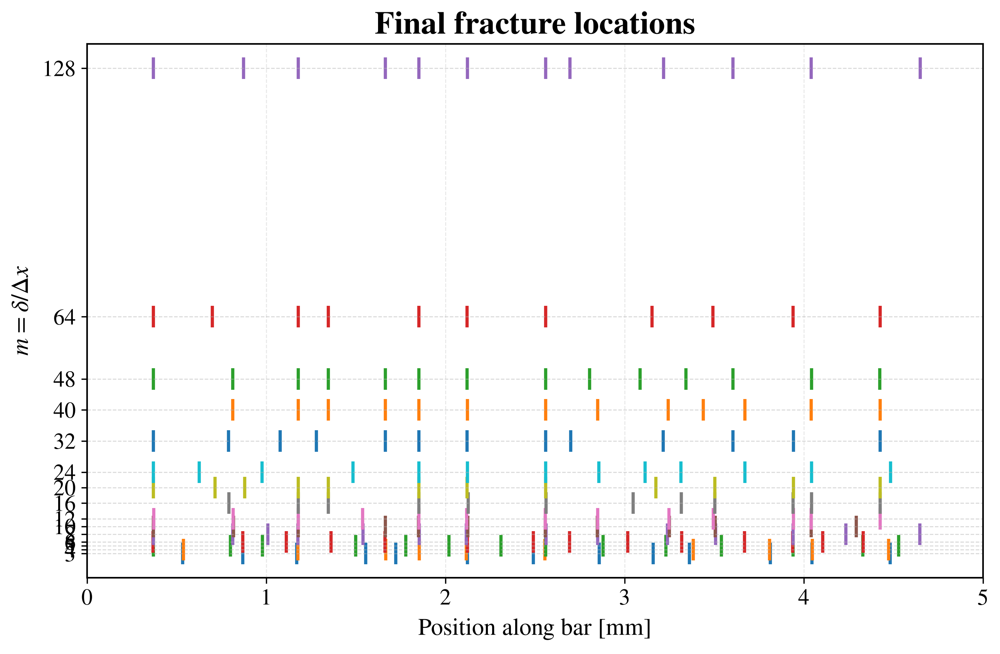

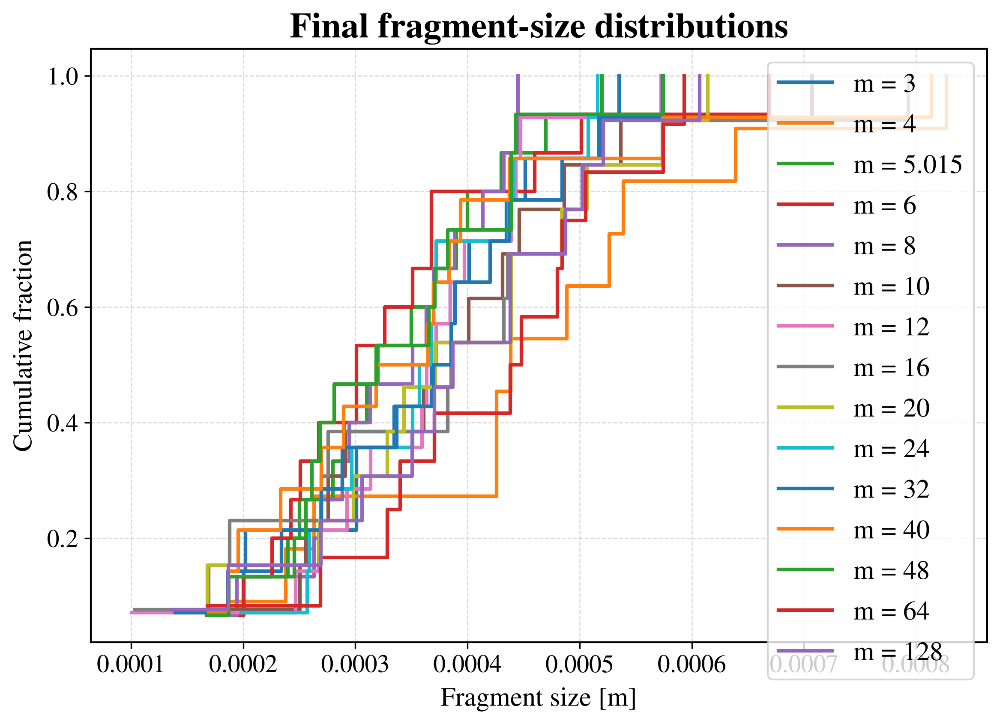

,m,n_fragments,median,std,min,q25,q75,max
0,3.000,14,0.000368,0.000106,0.000167,0.000301,0.000426,0.000535
1,4.000,11,0.000439,0.000177,0.000188,0.000345,0.000533,0.000827
2,5.015,15,0.000320,0.000095,0.000180,0.000265,0.000395,0.000520
3,6.000,15,0.000301,0.000126,0.000167,0.000247,0.000368,0.000669
4,8.000,15,0.000351,0.000084,0.000169,0.000279,0.000401,0.000445
5,10.000,13,0.000371,0.000136,0.000186,0.000276,0.000446,0.000707
6,12.000,14,0.000368,0.000108,0.000100,0.000298,0.000429,0.000573
7,16.000,13,0.000386,0.000180,0.000103,0.000270,0.000486,0.000793
8,20.000,13,0.000371,0.000136,0.000165,0.000298,0.000484,0.000614
9,24.000,14,0.000363,0.000092,0.000198,0.000276,0.000420,0.000516


,m,mean_symmetric_distance,hausdorff_distance
0,3.000,0.000088,0.000208
1,4.000,0.000086,0.000305
2,5.015,0.000094,0.000288
3,6.000,0.000078,0.000318
4,8.000,0.000055,0.000193
5,10.000,0.000054,0.000356
6,12.000,0.000060,0.000222
7,16.000,0.000092,0.000422
8,20.000,0.000067,0.000224
9,24.000,0.000083,0.000246


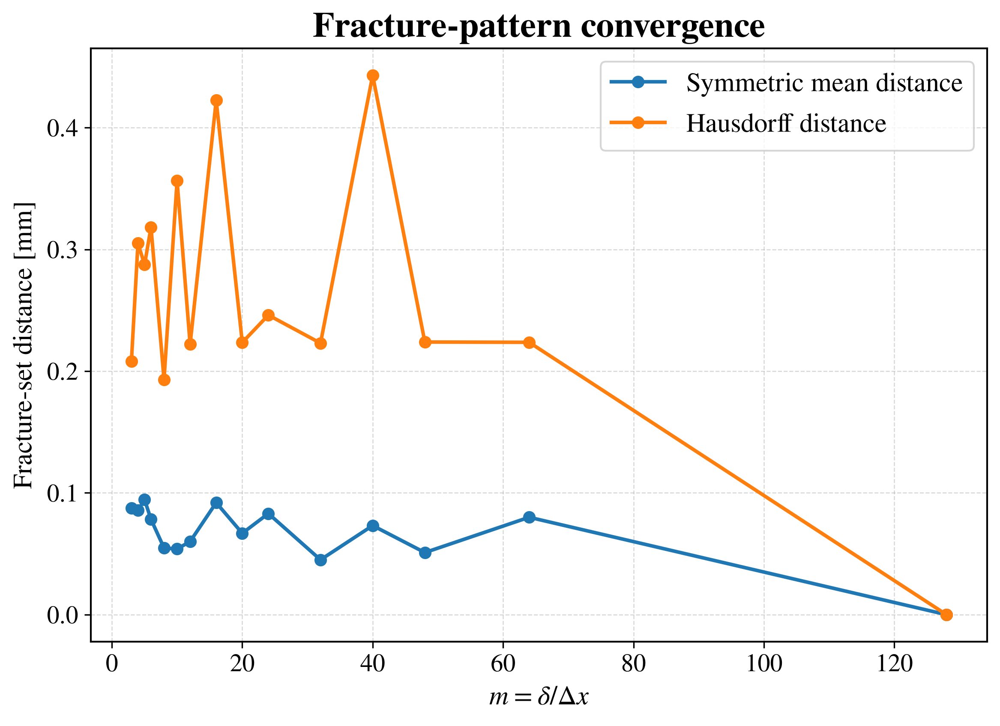

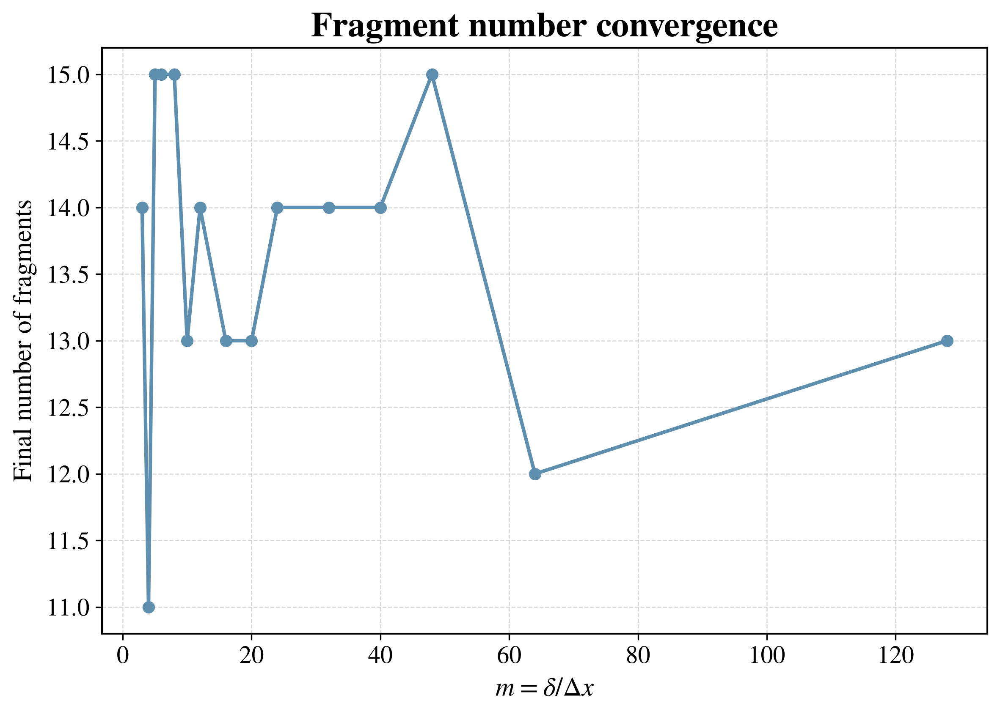

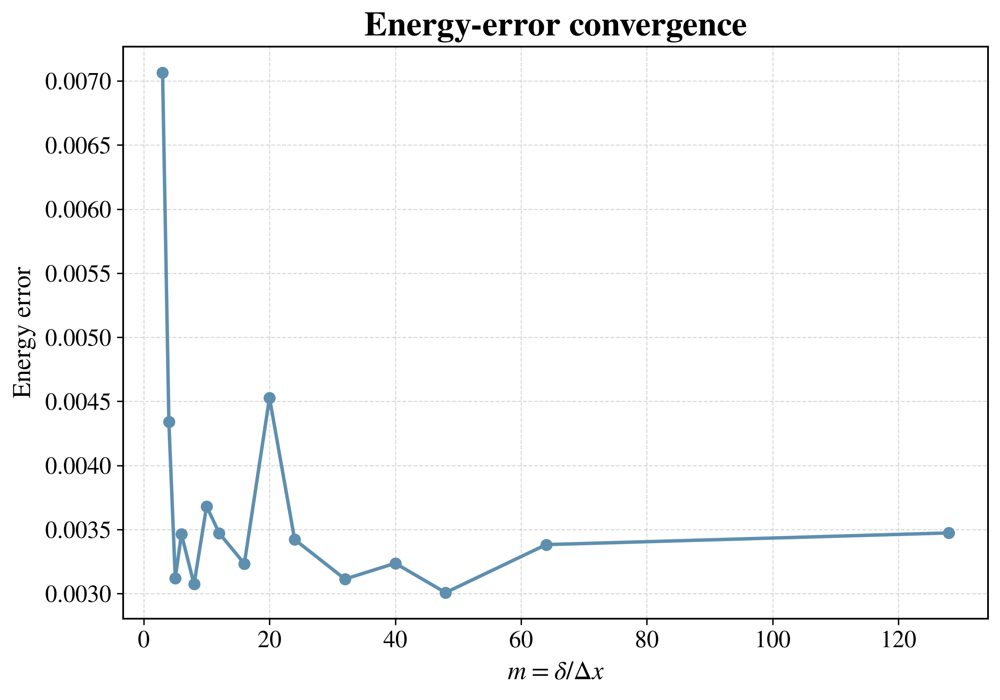

In [24]:
path = Path("data/PD/convergence_m_conical")

ms = [3, 4, 5.015, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48, 64, 128]
plot_fracture_locations(path, ms)
plot_fragment_ecdf(path, ms)
stats = fragment_statistics(path, ms)
display(stats)
set_error = fracture_set_convergence(
    path,
    ms,
    reference_m=128,
)

display(set_error)

plot_fracture_set_convergence(set_error)
plot_fragment_number_vs_m(path, ms)
plot_energy_error_vs_m(path, ms)

---
## <center> Horizon convergence for Peridynamics